# METAMER-SAE — Notebook 08
## Paired Metamer Representation Evaluation

**Purpose.** Apply the *frozen* natural-image-trained PCA and TopK SAE representations to paired Feather source / standard-metamer / adversarial-metamer stimuli. Debug on the fixed 8-triplet development split, then evaluate the 32-triplet primary split. Keep the 8 reserve triplets untouched.

**Operational research question.** Do sparse features learned from natural-image observer activations reveal structured differences between natural photographs and model metamers generated by standard-trained and adversarially trained visual networks, and how do these feature-level differences compare with a linear PCA representation?

**Notebook boundaries**
- Primary representation: frozen seed-123, 4× TopK-64 SAE; seed-42 is a separately analysed robustness replicate.
- PCA: reuse the saved 384-component fitted basis; report the preselected 16-component working baseline and a pre-existing 64-component sensitivity analysis. No PCA refitting.
- Input: pooled 384-D ConvNeXt-Tiny Stage-3 observer activations. Mean-centre SAE inputs with the exact saved Imagenette training mean; pass raw activations to the saved scikit-learn PCA object, which applies its own fitted centring.
- Evaluation: paired triplet-level metrics, paired uncertainty, feature-wise changes and a separate raw-spatial-observer diagnostic. The pooled SAE is **not** treated as a spatial SAE.
- No human behavioural data, recognisability analysis, brain/fMRI analysis, new training, or reserve-set analysis.

**Visual design.** The figure suite uses publication-style paired comparisons, small-multiple panels, restrained colour, clear uncertainty, and high-resolution PNG plus vector PDF exports. It adapts the visual grammar discussed in the project plan: Feather-style paired stimulus/model comparisons, Conwell-style controlled condition organisation, and Anthropic-style feature atlases. It does not reproduce any paper figure.

## 0. Runtime, reproducibility and output locations

Use the same Google Drive mount and project root as Notebook 07. The pinned Overcomplete package is needed only to reconstruct the frozen SAE architecture and load the existing checkpoints; **this notebook performs no SAE training**.

The runtime must be Python 3.12 (`< 3.13`), matching the validated Notebook 06 environment.

In [ ]:
from pathlib import Path
import os, sys, json, math, hashlib, platform, warnings, textwrap
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches, lines
from matplotlib.colors import TwoSlopeNorm
from PIL import Image
from IPython.display import display

import torch
from scipy import stats
import joblib

SEED = 20261119
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Platform:", platform.platform())

assert sys.version_info < (3, 13), (
    f"This notebook expects Python 3.12 (<3.13); found {sys.version}. "
    "Select the Colab 2026.07 runtime before continuing."
)

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
CUDA available: True
Platform: Linux-6.6.159+-x86_64-with-glibc2.35


In [ ]:
# Install the exact package used to build the frozen TopKSAE checkpoints.
# This is an environment setup step only; no model is trained or modified.
%pip install --no-deps --no-cache-dir "overcomplete==0.3.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 7.4 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

PROJECT_ROOT = Path('/content/gdrive/MyDrive/metamer-sae')
assert PROJECT_ROOT.exists(), f"Project root not found: {PROJECT_ROOT}"

OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'paired_metamer_evaluation'
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
ARRAY_DIR = OUTPUT_DIR / 'arrays'
for folder in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, ARRAY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Notebook 08 outputs:", OUTPUT_DIR)

Mounted at /content/gdrive
Project: /content/gdrive/MyDrive/metamer-sae
Notebook 08 outputs: /content/gdrive/MyDrive/metamer-sae/outputs/paired_metamer_evaluation


## 1. Freeze the analysis specification before primary evaluation

The primary evaluation metrics, PCA component counts, seed handling, feature-ranking rule and plots are specified here before the 32 primary triplets are loaded. The development split is used first to validate the paired data flow and metric implementation. The primary split is then evaluated with the same frozen procedure.

PCA-16 remains the preselected working baseline. PCA-64 is a predeclared dimensionality sensitivity analysis based on the existing Notebook 04 component-retention table; it is not selected by looking at Feather primary results. PCA-64 and SAE TopK-64 have different representational structures and should not be described as perfectly capacity-matched.

In [ ]:
# -----------------------
# Frozen study constants
# -----------------------
INPUT_DIM = 384
DICT_WIDTH = 1536
TOP_K = 64
PRIMARY_SEED = 123
REPLICATE_SEED = 42
PCA_RUN_ID = 'pca_20261119T065920Z'
PCA_COMPONENTS_PRIMARY = 16
PCA_COMPONENTS_SENSITIVITY = 64
EXPECTED_SPLIT_COUNTS = {'development': 8, 'primary_evaluation': 32, 'reserve': 8}
EXPECTED_DEVELOPMENT_IDS = [
    'feather_0000', 'feather_0027', 'feather_0084', 'feather_0097',
    'feather_0119', 'feather_0199', 'feather_0260', 'feather_0308'
]
BOOTSTRAP_REPS = 10000
BOOTSTRAP_SEED = 20261119
TOP_N_NATURAL_FEATURES = 40
DO_SPATIAL_DIAGNOSTICS = True
MAKE_PRIMARY_IMAGE_GALLERY = True

PRIMARY_REL = 'outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt'
REPLICATE_REL = 'outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42/best_model.pt'
SELECTION_PATH = PROJECT_ROOT / 'outputs/topk_sae/selected_sae_checkpoint.json'
PREP_DIR = PROJECT_ROOT / 'outputs/sae_preparation'
MEAN_PATH = PREP_DIR / 'training_activation_mean.npy'
TRAIN_CENTERED_PATH = PREP_DIR / 'train_centered_activations.npy'
VAL_CENTERED_PATH = PREP_DIR / 'validation_centered_activations.npy'

PCA_RUN_DIR = PROJECT_ROOT / 'representations' / 'pca' / 'runs' / PCA_RUN_ID
PCA_MODEL_PATH = PCA_RUN_DIR / 'pca_full_384_components.joblib'
PCA_CONFIG_PATH = PCA_RUN_DIR / 'pca_run_config.json'
PCA_RETENTION_PATH = PCA_RUN_DIR / 'pca_component_retention_metrics.csv'

STIM_MANIFEST_PATH = PROJECT_ROOT / 'stimuli' / 'manifests' / 'stimulus_manifest.csv'
FEATHER_META_PATHS = {
    'source': PROJECT_ROOT / 'activations/feather/source/metadata.csv',
    'standard': PROJECT_ROOT / 'activations/feather/standard_resnet50/metadata.csv',
    'adversarial': PROJECT_ROOT / 'activations/feather/adversarial_resnet50/metadata.csv',
}
FEATHER_POOL_PATHS = {
    'source': PROJECT_ROOT / 'activations/feather/source/pooled_activations.npy',
    'standard': PROJECT_ROOT / 'activations/feather/standard_resnet50/pooled_activations.npy',
    'adversarial': PROJECT_ROOT / 'activations/feather/adversarial_resnet50/pooled_activations.npy',
}
FEATHER_SPATIAL_PATHS = {
    'source': PROJECT_ROOT / 'activations/feather/source/spatial_activations.npy',
    'standard': PROJECT_ROOT / 'activations/feather/standard_resnet50/spatial_activations.npy',
    'adversarial': PROJECT_ROOT / 'activations/feather/adversarial_resnet50/spatial_activations.npy',
}

required_paths = [SELECTION_PATH, MEAN_PATH, TRAIN_CENTERED_PATH, VAL_CENTERED_PATH,
                  PCA_MODEL_PATH, PCA_CONFIG_PATH, PCA_RETENTION_PATH, STIM_MANIFEST_PATH,
                  *FEATHER_META_PATHS.values(), *FEATHER_POOL_PATHS.values(),
                  PROJECT_ROOT / PRIMARY_REL, PROJECT_ROOT / REPLICATE_REL]
missing_paths = [str(p) for p in required_paths if not p.exists()]
assert not missing_paths, "Missing required project artifacts:\n" + "\n".join(missing_paths)

PROTOCOL = {
    'notebook': '08_paired_metamer_evaluation.ipynb',
    'project': 'metamer-sae',
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'pca_run_id': PCA_RUN_ID,
    'pca_components_primary': PCA_COMPONENTS_PRIMARY,
    'pca_components_sensitivity': PCA_COMPONENTS_SENSITIVITY,
    'sae_architecture': {'input_dim': INPUT_DIM, 'dictionary_width': DICT_WIDTH, 'top_k': TOP_K},
    'primary_seed': PRIMARY_SEED,
    'replicate_seed': REPLICATE_SEED,
    'bootstrap_reps': BOOTSTRAP_REPS,
    'bootstrap_seed': BOOTSTRAP_SEED,
    'primary_metrics': ['raw_384', 'pca_16', 'pca_64', 'sae_seed123', 'sae_seed42'],
    'pairing': 'source paired to standard and adversarial metamer by stimulus_id',
    'feature_ranking': 'top features ranked by activation mass on Imagenette training only',
    'reserve_policy': 'reserve triplets are not indexed, loaded, encoded or analysed',
    'behavioural_policy': 'no human behavioural data loaded or analysed',
    'spatial_policy': 'raw ConvNeXt observer spatial diagnostics only; pooled SAE is not applied spatially',
}
protocol_text = json.dumps(PROTOCOL, sort_keys=True, indent=2)
PROTOCOL_SHA256 = hashlib.sha256(protocol_text.encode('utf-8')).hexdigest()
with open(OUTPUT_DIR / 'analysis_protocol.json', 'w') as f:
    json.dump({**PROTOCOL, 'protocol_sha256': PROTOCOL_SHA256,
               'primary_evaluation_access_at_protocol_freeze': False}, f, indent=2)
print("Frozen protocol SHA-256:", PROTOCOL_SHA256)

Frozen protocol SHA-256: e971417ceecc721cd5ffe4fb0217db92c89842f8ae614c09638ff9e7f84cd610


## 2. Load and audit the frozen PCA and SAE representations

PCA was fitted on the 9,469 Imagenette training observations and saved with all 384 components. We load that object and select its first 16 or 64 components at transform/reconstruction time. No `fit`, `fit_transform`, scaler fit or other training operation is allowed here.

The SAE primary and replicate checkpoints are loaded with PyTorch restricted deserialization (`weights_only=True`) and strict state-dictionary matching. Their preprocessing is the saved Imagenette training-mean subtraction only.

In [ ]:
with open(SELECTION_PATH, 'r') as f:
    selection_manifest = json.load(f)
print("Selected checkpoint manifest:")
print(json.dumps(selection_manifest, indent=2)[:6000])

training_mean = np.load(MEAN_PATH).astype(np.float32)
X_train_centered = np.load(TRAIN_CENTERED_PATH, mmap_mode='r')
X_val_centered = np.load(VAL_CENTERED_PATH, mmap_mode='r')
assert training_mean.shape == (INPUT_DIM,)
assert X_train_centered.shape == (9469, INPUT_DIM)
assert X_val_centered.shape == (3925, INPUT_DIM)
assert np.isfinite(training_mean).all()
assert np.isfinite(X_train_centered).all() and np.isfinite(X_val_centered).all()
print("Saved SAE preprocessing validated:", training_mean.shape, X_train_centered.shape, X_val_centered.shape)

with open(PCA_CONFIG_PATH, 'r') as f:
    pca_config = json.load(f)
print("PCA config run ID:", pca_config.get('run_id', pca_config.get('pca_run_id', 'not recorded')))
print("PCA config excerpt:", json.dumps(pca_config, indent=2)[:2500])

# This table is read-only provenance from Notebook 04. It verifies that 16 PCs
# remain the selected working baseline and that 64 PCs are a predeclared
# dimensionality sensitivity analysis; it is not used to select on Feather data.
pca_retention = pd.read_csv(PCA_RETENTION_PATH)
print("PCA retention table columns:", pca_retention.columns.tolist())
display(pca_retention.head(12))

pca_model = joblib.load(PCA_MODEL_PATH)
assert hasattr(pca_model, 'components_') and hasattr(pca_model, 'mean_')
assert pca_model.components_.shape == (INPUT_DIM, INPUT_DIM), pca_model.components_.shape
assert pca_model.mean_.shape == (INPUT_DIM,)
assert getattr(pca_model, 'whiten', False) is False, "Expected the original non-whitened PCA."
assert int(getattr(pca_model, 'n_components_', 0)) == INPUT_DIM
assert PCA_COMPONENTS_SENSITIVITY <= pca_model.components_.shape[0]
print("Loaded frozen PCA:", pca_model.components_.shape,
      "explained variance first 16:", float(pca_model.explained_variance_ratio_[:16].sum()),
      "first 64:", float(pca_model.explained_variance_ratio_[:64].sum()))

import importlib.metadata as importlib_metadata
try:
    overcomplete_version = importlib_metadata.version('overcomplete')
except importlib_metadata.PackageNotFoundError:
    overcomplete_version = 'not-installed'
assert overcomplete_version == '0.3.0', f"Expected Overcomplete 0.3.0, found {overcomplete_version}"
from overcomplete.sae import TopKSAE
from torch.torch_version import TorchVersion

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def safe_load_checkpoint(path):
    with torch.serialization.safe_globals([TorchVersion]):
        return torch.load(path, map_location='cpu', weights_only=True)

def build_and_load_sae(path):
    checkpoint = safe_load_checkpoint(path)
    model = TopKSAE(input_shape=INPUT_DIM, nb_concepts=DICT_WIDTH, top_k=TOP_K)
    state = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))
    incompat = model.load_state_dict(state, strict=True)
    assert not incompat.missing_keys and not incompat.unexpected_keys
    model.to(DEVICE).eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    return model, checkpoint

primary_checkpoint_path = PROJECT_ROOT / PRIMARY_REL
replicate_checkpoint_path = PROJECT_ROOT / REPLICATE_REL
primary_model, primary_checkpoint = build_and_load_sae(primary_checkpoint_path)
replicate_model, replicate_checkpoint = build_and_load_sae(replicate_checkpoint_path)
print("Overcomplete:", overcomplete_version, "| device:", DEVICE)
print("Primary SAE:", primary_checkpoint_path)
print("Replicate SAE:", replicate_checkpoint_path)

Selected checkpoint manifest:
{
  "project": "Metamer-SAE",
  "selection_timestamp_utc": "2026-11-19T16:54:19.906690+00:00",
  "selection_status": "provisional_validation_based_selection",
  "selected_configuration": {
    "expansion_factor": 4,
    "dictionary_size": 1536,
    "top_k": 64
  },
  "selected_run_id": "topk_4x_k64_seed123",
  "selected_stage": "200_epoch_replay_and_extend",
  "selected_seed": 123,
  "selected_best_epoch": 125,
  "selected_validation_mse": 0.0016301164756807836,
  "selected_validation_active_features": 1239,
  "selected_checkpoint_path": "/content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt",
  "pca_validation_mse": 0.0037489,
  "improvement_vs_pca_percent": 56.51747244042829,
  "selection_rule": "Lowest directly verified validation reconstruction MSE among the original and extended 4x K64 seed 42 and seed 123 checkpoints. The other seed is retained as a robustness replicate.",
  "held_out_feather_data_us

,n_components,cumulative_variance_explained,train_mse,validation_mse,validation_mse_se,train_relative_mse_to_mean_baseline,validation_relative_mse_to_mean_baseline
0,1,0.930437,0.006509,0.006525,0.000041,0.069563,0.071725
1,2,0.935557,0.006030,0.006014,0.000031,0.064443,0.066108
2,4,0.942273,0.005402,0.005400,0.000028,0.057728,0.059359
3,8,0.951039,0.004581,0.004586,0.000025,0.048961,0.050409
4,16,0.960058,0.003737,0.003749,0.000022,0.039942,0.041210
5,24,0.965056,0.003270,0.003287,0.000020,0.034944,0.036132
6,32,0.968764,0.002923,0.002948,0.000018,0.031236,0.032407
7,48,0.974194,0.002415,0.002450,0.000016,0.025806,0.026935
8,64,0.978246,0.002036,0.002081,0.000014,0.021754,0.022871
9,96,0.984131,0.001485,0.001541,0.000010,0.015869,0.016935


Loaded frozen PCA: (384, 384) explained variance first 16: 0.9600580930709839 first 64: 0.9782463908195496
Overcomplete: 0.3.0 | device: cuda
Primary SAE: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt
Replicate SAE: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42/best_model.pt


## 3. Resolve the fixed Feather triplet splits and activation-row mappings

The manifest defines the immutable 8 / 32 / 8 split. Each condition's metadata includes `activation_index`; that field—not DataFrame row order—is used to retrieve activation rows. The source metadata identifies triplets from filenames such as `feather_0000_source.png`; standard and adversarial metadata use `sample_id`.

Only the development and primary activation-row indices are constructed and subsequently used. Reserve IDs are recorded for provenance, but no reserve activation-row indices are constructed and no reserve activation array values are accessed.

In [ ]:
stim_manifest = pd.read_csv(STIM_MANIFEST_PATH)
print("Stimulus manifest:", stim_manifest.shape)
print("Manifest columns:", stim_manifest.columns.tolist())

def find_col(df, candidates):
    lower = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lower:
            return lower[candidate.lower()]
    return None

manifest_id_col = find_col(stim_manifest, ['stimulus_id', 'image_id', 'sample_id', 'feather_id'])
manifest_split_col = find_col(stim_manifest, ['subset', 'split', 'partition', 'allocation', 'dataset_split'])
assert manifest_id_col and manifest_split_col, f"Cannot identify manifest ID/split columns: {stim_manifest.columns.tolist()}"

manifest = stim_manifest.copy()
manifest['stimulus_id_canonical'] = manifest[manifest_id_col].astype(str).str.strip()
manifest['_split_text'] = manifest[manifest_split_col].astype(str).str.lower().str.replace('-', '_').str.replace(' ', '_')

def canonical_split(value):
    value = str(value).lower().replace('-', '_').replace(' ', '_')
    if 'develop' in value or value in {'dev', 'development_set'}:
        return 'development'
    if 'reserve' in value or 'sensitivity' in value:
        return 'reserve'
    if 'primary' in value or 'evaluation' in value or value in {'test', 'held_out'}:
        return 'primary_evaluation'
    return None

manifest['analysis_split'] = manifest['_split_text'].map(canonical_split)
assert manifest['analysis_split'].notna().all(), (
    "Unrecognised split labels: " + str(manifest.loc[manifest.analysis_split.isna(), manifest_split_col].unique().tolist())
)
assert manifest['stimulus_id_canonical'].is_unique, "Duplicate stimulus IDs in stimulus manifest."
split_counts = manifest['analysis_split'].value_counts().to_dict()
assert split_counts == EXPECTED_SPLIT_COUNTS, f"Expected fixed split {EXPECTED_SPLIT_COUNTS}, found {split_counts}"

split_ids = {
    split: sorted(manifest.loc[manifest.analysis_split == split, 'stimulus_id_canonical'].tolist())
    for split in EXPECTED_SPLIT_COUNTS
}
assert split_ids['development'] == sorted(EXPECTED_DEVELOPMENT_IDS), (
    "Development IDs differ from the verified Notebook 07 allocation."
)
assert set(split_ids['development']).isdisjoint(split_ids['primary_evaluation'])
assert set(split_ids['development']).isdisjoint(split_ids['reserve'])
assert set(split_ids['primary_evaluation']).isdisjoint(split_ids['reserve'])

feather_meta = {k: pd.read_csv(v) for k, v in FEATHER_META_PATHS.items()}
metadata_maps = {}
metadata_path_maps = {}

for condition, df in feather_meta.items():
    assert 'activation_index' in df.columns, f"{condition}: activation_index missing."
    if condition == 'source':
        assert 'filename' in df.columns, f"source metadata has no filename column: {df.columns.tolist()}"
        ids = []
        for filename in df['filename'].astype(str):
            stem = Path(filename).stem
            import re
            match = re.fullmatch(r'(feather_\d+)_source', stem, flags=re.IGNORECASE)
            assert match, f"Cannot extract source stimulus ID from {filename}"
            ids.append(match.group(1))
    else:
        id_col = find_col(df, ['sample_id', 'stimulus_id', 'image_id', 'feather_id'])
        assert id_col, f"{condition}: no ID column in {df.columns.tolist()}"
        ids = df[id_col].astype(str).str.strip().tolist()

    indices = pd.to_numeric(df['activation_index'], errors='raise').to_numpy()
    assert np.isfinite(indices).all() and np.all(indices == np.floor(indices))
    indices = indices.astype(int)
    assert len(ids) == len(df) and len(set(ids)) == len(ids)
    assert len(set(indices.tolist())) == len(df)
    assert np.array_equal(np.sort(indices), np.arange(len(df))), (
        f"{condition}: activation_index must map metadata rows one-to-one onto array rows 0..{len(df)-1}."
    )
    metadata_maps[condition] = dict(zip(ids, indices))
    if 'relative_path' in df.columns:
        metadata_path_maps[condition] = dict(zip(ids, df['relative_path'].astype(str)))

    print(f"{condition}: {len(ids)} metadata identities mapped; activation rows {indices.min()}–{indices.max()}")

for split, ids in split_ids.items():
    for condition, mapping in metadata_maps.items():
        missing = sorted(set(ids) - set(mapping))
        assert not missing, f"{condition}: {split} IDs missing from activation metadata: {missing[:5]}"

# Build activation-row indices only for development and primary evaluation.
# Reserve identities remain in the ledger, but no reserve activation indices are constructed.
indices_by_split = {
    split: {
        condition: np.asarray([metadata_maps[condition][sid] for sid in split_ids[split]], dtype=int)
        for condition in ('source', 'standard', 'adversarial')
    }
    for split in ('development', 'primary_evaluation')
}

# Persist the split ledger (recording reserve identities does not load their activations).
split_ledger = pd.DataFrame([
    {'stimulus_id': sid, 'split': split}
    for split, ids in split_ids.items() for sid in ids
])
split_ledger.to_csv(TABLE_DIR / 'fixed_triplet_split_ledger.csv', index=False)
print("\nFixed split counts:", split_counts)
print("Development IDs:", split_ids['development'])
print("Primary evaluation IDs:", len(split_ids['primary_evaluation']))
print("Reserve IDs recorded only; reserve activation rows will not be indexed:", len(split_ids['reserve']))

Stimulus manifest: (48, 45)
Manifest columns: ['stimulus_id', 'source_image_id', 'subset', 'generator_standard_experiment', 'generator_standard_model', 'generator_adversarial_experiment', 'generator_adversarial_model', 'generation_layer', 'random_sampling_seed', 'allocation_method', 'complete_url_triplet', 'source_path', 'standard_metamer_path', 'adversarial_metamer_path', 'source_url', 'standard_metamer_url', 'adversarial_metamer_url', 'retrieval_status', 'all_images_downloaded', 'dimensions_match', 'source_width', 'source_height', 'source_mode', 'source_channels', 'source_format', 'source_file_size_bytes', 'source_sha256', 'source_saved_path', 'standard_width', 'standard_height', 'standard_mode', 'standard_channels', 'standard_format', 'standard_file_size_bytes', 'standard_sha256', 'standard_saved_path', 'adversarial_width', 'adversarial_height', 'adversarial_mode', 'adversarial_channels', 'adversarial_format', 'adversarial_file_size_bytes', 'adversarial_sha256', 'adversarial_saved_p

## 4. Core metric and encoding functions

All source–metamer comparisons are paired by `stimulus_id`. Distances are calculated within each representation. Raw L2 distances from PCA and SAE are not interpreted as directly commensurate because their coordinate systems, scales and sparsity structures differ; comparison across methods focuses on direction, paired effect size, normalized distance, and reconstruction behaviour.

In [ ]:
def encode_sae(model, X, batch_size=128):
    """Encode centered 384-D inputs with a frozen TopKSAE."""
    codes_parts, recon_parts = [], []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = np.array(X[start:start + batch_size], dtype=np.float32, copy=True)
            xb = torch.tensor(batch, dtype=torch.float32, device=DEVICE)
            _, codes, reconstruction = model(xb)
            codes_parts.append(codes.detach().cpu().numpy())
            recon_parts.append(reconstruction.detach().cpu().numpy())
    return np.concatenate(codes_parts, axis=0), np.concatenate(recon_parts, axis=0)


def cosine_similarity(a, b, eps=1e-12):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    if denom < eps:
        return np.nan
    return float(np.dot(a, b) / denom)


def vector_distance_metrics(a, b):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()
    delta = b - a
    l2 = float(np.linalg.norm(delta))
    l1 = float(np.abs(delta).sum())
    source_norm = float(np.linalg.norm(a))
    return {
        'distance_l2': l2,
        'distance_l1': l1,
        'relative_l2_source_norm': float(l2 / max(source_norm, 1e-12)),
        'cosine_similarity': cosine_similarity(a, b),
    }


def support_jaccard(a, b):
    sa = np.flatnonzero(np.asarray(a) != 0)
    sb = np.flatnonzero(np.asarray(b) != 0)
    union = np.union1d(sa, sb)
    if len(union) == 0:
        return 1.0
    return float(len(np.intersect1d(sa, sb)) / len(union))


def process_split(split_name, ids, indices):
    """Encode one partition only; returns per-image, paired and latent arrays."""
    print(f"\nLoading {split_name}: {len(ids)} triplets / {len(ids)*3} stimuli")
    raw = {}
    for condition in ('source', 'standard', 'adversarial'):
        arr = np.load(FEATHER_POOL_PATHS[condition], mmap_mode='r')
        assert arr.ndim == 2 and arr.shape == (48, INPUT_DIM), (condition, arr.shape)
        # Only this split's exact activation_index values are accessed.
        selected = np.asarray(arr[indices[condition]], dtype=np.float32)
        assert selected.shape == (len(ids), INPUT_DIM)
        assert np.isfinite(selected).all()
        raw[condition] = selected
        del arr

    centered = {condition: (values - training_mean[None, :]).astype(np.float32)
                for condition, values in raw.items()}
    result = {'ids': list(ids), 'raw': raw, 'centered': centered,
              'pca_scores': {}, 'pca_recons': {}, 'sae_codes': {}, 'sae_recons': {}}

    # Use one transform from the original full fitted PCA basis; do not refit.
    pca_scores_full = {condition: pca_model.transform(raw[condition]) for condition in raw}
    assert all(v.shape == (len(ids), INPUT_DIM) for v in pca_scores_full.values())
    for k, name in [(PCA_COMPONENTS_PRIMARY, 'pca_16'), (PCA_COMPONENTS_SENSITIVITY, 'pca_64')]:
        result['pca_scores'][name] = {c: pca_scores_full[c][:, :k].copy() for c in raw}
        result['pca_recons'][name] = {}
        components = pca_model.components_[:k]
        for condition in raw:
            scores = result['pca_scores'][name][condition]
            reconstructed = pca_model.mean_[None, :] + scores @ components
            result['pca_recons'][name][condition] = reconstructed.astype(np.float32)

    for seed_name, model in [('seed123', primary_model), ('seed42', replicate_model)]:
        result['sae_codes'][seed_name] = {}
        result['sae_recons'][seed_name] = {}
        for condition in raw:
            codes, reconstruction = encode_sae(model, centered[condition])
            assert codes.shape == (len(ids), DICT_WIDTH)
            assert reconstruction.shape == (len(ids), INPUT_DIM)
            assert np.isfinite(codes).all() and np.isfinite(reconstruction).all()
            active_per_example = np.count_nonzero(codes, axis=1)
            assert np.all(active_per_example == TOP_K), (
                f"{seed_name}/{condition}: expected exactly {TOP_K} nonzero codes per image; "
                f"observed {np.unique(active_per_example).tolist()}"
            )
            result['sae_codes'][seed_name][condition] = codes
            result['sae_recons'][seed_name][condition] = reconstruction

    # Per-stimulus reconstruction records.
    stimulus_rows = []
    for condition in ('source', 'standard', 'adversarial'):
        for i, sid in enumerate(ids):
            for method in ('pca_16', 'pca_64'):
                x = raw[condition][i]
                xhat = result['pca_recons'][method][condition][i]
                stimulus_rows.append({
                    'split': split_name, 'stimulus_id': sid, 'condition': condition,
                    'representation': method,
                    'reconstruction_mse': float(np.mean((x - xhat) ** 2)),
                    'active_features': np.nan,
                })
            for seed_name in ('seed123', 'seed42'):
                x = centered[condition][i]
                xhat = result['sae_recons'][seed_name][condition][i]
                codes = result['sae_codes'][seed_name][condition][i]
                stimulus_rows.append({
                    'split': split_name, 'stimulus_id': sid, 'condition': condition,
                    'representation': f'sae_{seed_name}',
                    'reconstruction_mse': float(np.mean((x - xhat) ** 2)),
                    'active_features': int(np.count_nonzero(codes)),
                })
    stimulus_df = pd.DataFrame(stimulus_rows)

    # Paired source-to-metamer comparisons.
    pair_rows = []
    for i, sid in enumerate(ids):
        for metamer_condition in ('standard', 'adversarial'):
            # Original observer space.
            pair_rows.append({
                'split': split_name, 'stimulus_id': sid,
                'metamer_condition': metamer_condition, 'representation': 'raw_384',
                **vector_distance_metrics(raw['source'][i], raw[metamer_condition][i]),
                'support_jaccard': np.nan, 'source_active_features': np.nan,
                'metamer_active_features': np.nan,
                'source_reconstruction_mse': np.nan, 'metamer_reconstruction_mse': np.nan,
                'delta_reconstruction_error': np.nan,
            })
            # PCA coordinates and original-space reconstruction differences.
            for method in ('pca_16', 'pca_64'):
                metric = vector_distance_metrics(result['pca_scores'][method]['source'][i],
                                                 result['pca_scores'][method][metamer_condition][i])
                source_mse = float(np.mean((raw['source'][i] - result['pca_recons'][method]['source'][i]) ** 2))
                metamer_mse = float(np.mean((raw[metamer_condition][i] - result['pca_recons'][method][metamer_condition][i]) ** 2))
                pair_rows.append({
                    'split': split_name, 'stimulus_id': sid,
                    'metamer_condition': metamer_condition, 'representation': method,
                    **metric, 'support_jaccard': np.nan,
                    'source_active_features': np.nan, 'metamer_active_features': np.nan,
                    'source_reconstruction_mse': source_mse,
                    'metamer_reconstruction_mse': metamer_mse,
                    'delta_reconstruction_error': metamer_mse - source_mse,
                })
            # SAE codes; feature indices are interpreted only within a seed.
            for seed_name in ('seed123', 'seed42'):
                source_code = result['sae_codes'][seed_name]['source'][i]
                metamer_code = result['sae_codes'][seed_name][metamer_condition][i]
                source_mse = float(np.mean((centered['source'][i] - result['sae_recons'][seed_name]['source'][i]) ** 2))
                metamer_mse = float(np.mean((centered[metamer_condition][i] - result['sae_recons'][seed_name][metamer_condition][i]) ** 2))
                pair_rows.append({
                    'split': split_name, 'stimulus_id': sid,
                    'metamer_condition': metamer_condition,
                    'representation': f'sae_{seed_name}',
                    **vector_distance_metrics(source_code, metamer_code),
                    'support_jaccard': support_jaccard(source_code, metamer_code),
                    'source_active_features': int(np.count_nonzero(source_code)),
                    'metamer_active_features': int(np.count_nonzero(metamer_code)),
                    'source_reconstruction_mse': source_mse,
                    'metamer_reconstruction_mse': metamer_mse,
                    'delta_reconstruction_error': metamer_mse - source_mse,
                })

    pair_df = pd.DataFrame(pair_rows)
    assert len(stimulus_df) == len(ids) * 3 * 4
    assert len(pair_df) == len(ids) * 2 * 5
    assert pair_df.groupby(['representation', 'metamer_condition']).size().eq(len(ids)).all()
    return result, stimulus_df, pair_df

print("Core metric functions defined.")

Core metric functions defined.


## 5. Development split — implementation and pairing check

Run the exact eight development triplets first. This is a code-path validation stage, not a new model-selection step. The same functions and metrics will be applied to the primary split without modification.

In [ ]:
development_result, development_stimulus_df, development_pair_df = process_split(
    'development', split_ids['development'], indices_by_split['development']
)

display(development_stimulus_df.groupby(['representation', 'condition']).agg(
    n=('stimulus_id', 'count'), mean_reconstruction_mse=('reconstruction_mse', 'mean'),
    mean_active_features=('active_features', 'mean')
).round(6))

display(development_pair_df.groupby(['representation', 'metamer_condition']).agg(
    n=('stimulus_id', 'count'), mean_distance_l2=('distance_l2', 'mean'),
    mean_relative_l2=('relative_l2_source_norm', 'mean'),
    mean_cosine=('cosine_similarity', 'mean'),
    mean_support_jaccard=('support_jaccard', 'mean'),
    mean_delta_reconstruction=('delta_reconstruction_error', 'mean')
).round(6))

development_stimulus_df.to_csv(TABLE_DIR / 'development_stimulus_metrics.csv', index=False)
development_pair_df.to_csv(TABLE_DIR / 'development_paired_metrics.csv', index=False)
assert development_result['raw']['source'].shape == (8, INPUT_DIM)
assert development_result['sae_codes']['seed123']['source'].shape == (8, DICT_WIDTH)
assert development_result['sae_codes']['seed42']['source'].shape == (8, DICT_WIDTH)
print("Development pipeline validation passed; no primary or reserve activations have been indexed yet.")


Loading development: 8 triplets / 24 stimuli


n  mean_reconstruction_mse  mean_active_features
representation condition                                                    
pca_16         adversarial  8                 0.005074                   NaN
               source       8                 0.005385                   NaN
               standard     8                 0.005034                   NaN
pca_64         adversarial  8                 0.003229                   NaN
               source       8                 0.003454                   NaN
               standard     8                 0.003285                   NaN
sae_seed123    adversarial  8                 0.002767                  64.0
               source       8                 0.002992                  64.0
               standard     8                 0.002952                  64.0
sae_seed42     adversarial  8                 0.002874                  64.0
               source       8                 0.002991                  64.0
               standard     8                 0.002932                  64.0

n  mean_distance_l2  mean_relative_l2  \
representation metamer_condition                                          
pca_16         adversarial        8          1.827344          0.616674   
               standard           8          3.593855          0.979468   
pca_64         adversarial        8          1.889444          0.563817   
               standard           8          3.646054          0.908515   
raw_384        adversarial        8          2.005566          0.056846   
               standard           8          3.754343          0.101986   
sae_seed123    adversarial        8          1.593623          0.521400   
               standard           8          2.996601          0.836583   
sae_seed42     adversarial        8          1.599840          0.522283   
               standard           8          3.009706          0.842668   

                                  mean_cosine  mean_support_jaccard  \
representation metamer_condition                                      
pca_16         adversarial           0.830276                   NaN   
               standard              0.813202                   NaN   
pca_64         adversarial           0.871514                   NaN   
               standard              0.844692                   NaN   
raw_384        adversarial           0.999748                   NaN   
               standard              0.999467                   NaN   
sae_seed123    adversarial           0.907359              0.700233   
               standard              0.876032              0.582965   
sae_seed42     adversarial           0.913744              0.719626   
               standard              0.876594              0.600590   

                                  mean_delta_reconstruction  
representation metamer_condition                             
pca_16         adversarial                        -0.000310  
               standard                           -0.000351  
pca_64         adversarial                        -0.000225  
               standard                           -0.000169  
raw_384        adversarial                              NaN  
               standard                                 NaN  
sae_seed123    adversarial                        -0.000226  
               standard                           -0.000040  
sae_seed42     adversarial                        -0.000117  
               standard                           -0.000059

Development pipeline validation passed; no primary or reserve activations have been indexed yet.


## 6. Freeze protocol record, then evaluate the 32 primary triplets

This cell updates the protocol record to show that development checks passed and the analysis specification is frozen. The next cell accesses only the primary evaluation activation indices. The reserve allocation remains untouched.

In [ ]:
protocol_path = OUTPUT_DIR / 'analysis_protocol.json'
with open(protocol_path, 'w') as f:
    json.dump({**PROTOCOL, 'protocol_sha256': PROTOCOL_SHA256,
               'development_validation_passed': True,
               'primary_evaluation_loaded': False,
               'reserve_activation_rows_accessed': False}, f, indent=2)

print("Frozen protocol saved:", protocol_path)
print("Protocol SHA-256:", PROTOCOL_SHA256)

Frozen protocol saved: /content/gdrive/MyDrive/metamer-sae/outputs/paired_metamer_evaluation/analysis_protocol.json
Protocol SHA-256: e971417ceecc721cd5ffe4fb0217db92c89842f8ae614c09638ff9e7f84cd610


In [ ]:
primary_result, primary_stimulus_df, primary_pair_df = process_split(
    'primary_evaluation', split_ids['primary_evaluation'], indices_by_split['primary_evaluation']
)

assert primary_result['raw']['source'].shape == (32, INPUT_DIM)
assert primary_result['sae_codes']['seed123']['source'].shape == (32, DICT_WIDTH)
assert primary_result['sae_codes']['seed42']['source'].shape == (32, DICT_WIDTH)
assert primary_pair_df['stimulus_id'].nunique() == 32
assert set(primary_pair_df['stimulus_id']) == set(split_ids['primary_evaluation'])
assert set(primary_pair_df['stimulus_id']).isdisjoint(split_ids['reserve'])

primary_stimulus_df.to_csv(TABLE_DIR / 'primary_stimulus_metrics.csv', index=False)
primary_pair_df.to_csv(TABLE_DIR / 'primary_paired_metrics.csv', index=False)

print("\nPrimary evaluation complete:", primary_pair_df['stimulus_id'].nunique(), "paired triplets")
print("Reserve activation rows accessed: 0")


Loading primary_evaluation: 32 triplets / 96 stimuli

Primary evaluation complete: 32 paired triplets
Reserve activation rows accessed: 0


## 7. Primary paired summaries and uncertainty

The main comparison is paired within the same 32 source identities. For distance metrics, `standard − adversarial > 0` means the standard metamer is farther from its source than the adversarial metamer in that representation. For support overlap and cosine similarity, the contrast is `adversarial − standard`, so positive values favour greater adversarial/source overlap.

The bootstrap resamples **triplets**, preserving the within-triplet standard/adversarial pairing. Intervals are percentile 95% bootstrap confidence intervals. The reported standardized paired effect is Cohen's *d*<sub>z</sub>. P-values are included as supplementary paired summaries and are not a substitute for effect sizes or uncertainty.

In [ ]:
def bootstrap_mean_ci(values, n_boot=BOOTSTRAP_REPS, seed=BOOTSTRAP_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(x), size=(n_boot, len(x)))
    boot_means = x[draws].mean(axis=1)
    return float(np.quantile(boot_means, 0.025)), float(np.quantile(boot_means, 0.975))


def paired_test_summary(x, y, contrast_name, direction_note, first_label, second_label):
    """Summarise a paired contrast; labels refer to the actual x and y order."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    diff = x - y
    lo, hi = bootstrap_mean_ci(diff)
    sd = float(np.std(diff, ddof=1)) if len(diff) > 1 else np.nan
    dz = float(np.mean(diff) / sd) if sd > 0 else np.nan
    try:
        wilcoxon_p = float(stats.wilcoxon(x, y, alternative='two-sided', zero_method='wilcox').pvalue)
    except Exception:
        wilcoxon_p = np.nan
    return {
        'contrast': contrast_name, 'n_triplets': int(len(diff)),
        'first_series': first_label, 'second_series': second_label,
        'mean_first': float(np.mean(x)), 'mean_second': float(np.mean(y)),
        'difference_definition': f'{first_label} - {second_label}',
        'mean_paired_difference': float(np.mean(diff)),
        'median_paired_difference': float(np.median(diff)),
        'bootstrap_95ci_low': lo, 'bootstrap_95ci_high': hi,
        'cohens_dz': dz, 'wilcoxon_p_two_sided': wilcoxon_p,
        'direction_interpretation': direction_note,
    }


def holm_bonferroni(p_values):
    """Holm family-wise adjustment, preserving NaNs."""
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(p.shape, np.nan, dtype=float)
    valid_idx = np.flatnonzero(np.isfinite(p))
    if not len(valid_idx):
        return adjusted
    order = valid_idx[np.argsort(p[valid_idx])]
    m = len(order)
    running = 0.0
    for rank, idx in enumerate(order):
        candidate = (m - rank) * p[idx]
        running = max(running, candidate)
        adjusted[idx] = min(running, 1.0)
    return adjusted

contrast_rows = []
representations = ['raw_384', 'pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']
for representation in representations:
    sub = primary_pair_df[primary_pair_df.representation == representation]
    wide = sub.pivot(index='stimulus_id', columns='metamer_condition', values='distance_l2').loc[split_ids['primary_evaluation']]
    contrast_rows.append(paired_test_summary(
        wide['standard'].values, wide['adversarial'].values,
        f'{representation}: L2 distance (standard − adversarial)',
        'Positive means standard metamer is farther from its source.',
        'standard', 'adversarial'
    ))
    wide_rel = sub.pivot(index='stimulus_id', columns='metamer_condition', values='relative_l2_source_norm').loc[split_ids['primary_evaluation']]
    contrast_rows.append(paired_test_summary(
        wide_rel['standard'].values, wide_rel['adversarial'].values,
        f'{representation}: relative L2 (standard − adversarial)',
        'Positive means standard metamer has greater source-normalized displacement.',
        'standard', 'adversarial'
    ))
    wide_cos = sub.pivot(index='stimulus_id', columns='metamer_condition', values='cosine_similarity').loc[split_ids['primary_evaluation']]
    contrast_rows.append(paired_test_summary(
        wide_cos['adversarial'].values, wide_cos['standard'].values,
        f'{representation}: cosine (adversarial − standard)',
        'Positive means adversarial metamer has greater cosine alignment with its source.',
        'adversarial', 'standard'
    ))
    if representation.startswith('sae_'):
        wide_j = sub.pivot(index='stimulus_id', columns='metamer_condition', values='support_jaccard').loc[split_ids['primary_evaluation']]
        contrast_rows.append(paired_test_summary(
            wide_j['adversarial'].values, wide_j['standard'].values,
            f'{representation}: support Jaccard (adversarial − standard)',
            'Positive means adversarial metamer shares more active SAE features with its source.',
            'adversarial', 'standard'
        ))

contrast_df = pd.DataFrame(contrast_rows)
contrast_df['wilcoxon_p_holm'] = holm_bonferroni(contrast_df['wilcoxon_p_two_sided'])
contrast_df['p_value_family'] = 'All paired contrasts in this table; Holm family-wise adjustment'
contrast_df.to_csv(TABLE_DIR / 'primary_paired_contrasts_bootstrap.csv', index=False)
display(contrast_df.round(5))

,contrast,n_triplets,first_series,second_series,mean_first,mean_second,difference_definition,mean_paired_difference,median_paired_difference,bootstrap_95ci_low,bootstrap_95ci_high,cohens_dz,wilcoxon_p_two_sided,direction_interpretation,wilcoxon_p_holm,p_value_family
0,raw_384: L2 distance (standard − adversarial),32,standard,adversarial,3.51393,1.88862,standard - adversarial,1.62531,1.36572,1.22524,2.07964,1.31505,0.0,Positive means standard metamer is farther fro...,0.0,All paired contrasts in this table; Holm famil...
1,raw_384: relative L2 (standard − adversarial),32,standard,adversarial,0.10312,0.05588,standard - adversarial,0.04723,0.04006,0.03650,0.05906,1.45039,0.0,Positive means standard metamer has greater so...,0.0,All paired contrasts in this table; Holm famil...
2,raw_384: cosine (adversarial − standard),32,adversarial,standard,0.99977,0.99943,adversarial - standard,0.00034,0.00032,0.00029,0.00040,2.15470,0.0,Positive means adversarial metamer has greater...,0.0,All paired contrasts in this table; Holm famil...
3,pca_16: L2 distance (standard − adversarial),32,standard,adversarial,3.32090,1.73932,standard - adversarial,1.58158,1.32026,1.16818,2.04934,1.23804,0.0,Positive means standard metamer is farther fro...,0.0,All paired contrasts in this table; Holm famil...
4,pca_16: relative L2 (standard − adversarial),32,standard,adversarial,1.61525,0.87356,standard - adversarial,0.74170,0.32406,0.45805,1.06256,0.83834,0.0,Positive means standard metamer has greater so...,0.0,All paired contrasts in this table; Holm famil...
5,pca_16: cosine (adversarial − standard),32,adversarial,standard,0.85238,0.71326,adversarial - standard,0.13912,0.00362,0.02416,0.29034,0.35420,0.0,Positive means adversarial metamer has greater...,0.0,All paired contrasts in this table; Holm famil...
6,pca_64: L2 distance (standard − adversarial),32,standard,adversarial,3.37833,1.78385,standard - adversarial,1.59448,1.32992,1.18633,2.05667,1.26269,0.0,Positive means standard metamer is farther fro...,0.0,All paired contrasts in this table; Holm famil...
7,pca_64: relative L2 (standard − adversarial),32,standard,adversarial,1.27911,0.66234,standard - adversarial,0.61677,0.31992,0.39699,0.87059,0.89492,0.0,Positive means standard metamer has greater so...,0.0,All paired contrasts in this table; Holm famil...
8,pca_64: cosine (adversarial − standard),32,adversarial,standard,0.87504,0.72788,adversarial - standard,0.14716,0.00936,0.04062,0.28401,0.41302,0.0,Positive means adversarial metamer has greater...,0.0,All paired contrasts in this table; Holm famil...
9,sae_seed123: L2 distance (standard − adversarial),32,standard,adversarial,2.65585,1.49767,standard - adversarial,1.15817,1.01265,0.89901,1.43695,1.49946,0.0,Positive means standard metamer is farther fro...,0.0,All paired contrasts in this table; Holm famil...


## 8. Reconstruction-error summaries

For PCA, reconstruction is performed in the original 384-D observer activation space using the saved PCA mean and the selected leading components. For SAE, reconstruction MSE is computed in the externally mean-centred 384-D space used during training. Within each method, source and metamer MSEs are directly comparable; cross-method MSE comparison is qualified by the differing centring implementations and representation budgets.

In [ ]:
reconstruction_summary = (primary_stimulus_df
    .groupby(['representation', 'condition'])
    .agg(n=('stimulus_id', 'count'), mean_mse=('reconstruction_mse', 'mean'),
         sd_mse=('reconstruction_mse', 'std'), median_mse=('reconstruction_mse', 'median'),
         mean_active_features=('active_features', 'mean'))
    .reset_index())
reconstruction_summary.to_csv(TABLE_DIR / 'primary_reconstruction_summary.csv', index=False)
display(reconstruction_summary.round(7))

# Paired reconstruction-error change: metamer MSE minus source MSE.
recon_delta_rows = []
for representation in ['pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']:
    sub = primary_pair_df[primary_pair_df.representation == representation]
    for condition in ['standard', 'adversarial']:
        vals = sub[sub.metamer_condition == condition]['delta_reconstruction_error'].to_numpy(float)
        lo, hi = bootstrap_mean_ci(vals)
        recon_delta_rows.append({
            'representation': representation, 'metamer_condition': condition,
            'n_triplets': int(np.isfinite(vals).sum()),
            'mean_delta_reconstruction_mse': float(np.nanmean(vals)),
            'median_delta_reconstruction_mse': float(np.nanmedian(vals)),
            'bootstrap_95ci_low': lo, 'bootstrap_95ci_high': hi,
        })
recon_delta_df = pd.DataFrame(recon_delta_rows)
recon_delta_df.to_csv(TABLE_DIR / 'primary_reconstruction_error_deltas.csv', index=False)
display(recon_delta_df.round(7))

,representation,condition,n,mean_mse,sd_mse,median_mse,mean_active_features
0,pca_16,adversarial,32,0.005940,0.001558,0.005549,NaN
1,pca_16,source,32,0.005970,0.001865,0.005684,NaN
2,pca_16,standard,32,0.005674,0.001460,0.005349,NaN
3,pca_64,adversarial,32,0.003689,0.001178,0.003535,NaN
4,pca_64,source,32,0.003704,0.001416,0.003636,NaN
5,pca_64,standard,32,0.003643,0.001118,0.003520,NaN
6,sae_seed123,adversarial,32,0.003179,0.000980,0.003092,64.0
7,sae_seed123,source,32,0.003043,0.001082,0.002989,64.0
8,sae_seed123,standard,32,0.003196,0.000911,0.002991,64.0
9,sae_seed42,adversarial,32,0.003109,0.000933,0.003071,64.0


,representation,metamer_condition,n_triplets,mean_delta_reconstruction_mse,median_delta_reconstruction_mse,bootstrap_95ci_low,bootstrap_95ci_high
0,pca_16,standard,32,-0.000295,-0.000029,-0.000529,-0.000080
1,pca_16,adversarial,32,-0.000029,0.000092,-0.000213,0.000139
2,pca_64,standard,32,-0.000062,0.000044,-0.000235,0.000108
3,pca_64,adversarial,32,-0.000015,0.000062,-0.000143,0.000099
4,sae_seed123,standard,32,0.000153,0.000196,0.000024,0.000281
5,sae_seed123,adversarial,32,0.000136,0.000142,0.000042,0.000223
6,sae_seed42,standard,32,0.000144,0.000170,0.000008,0.000278
7,sae_seed42,adversarial,32,0.000075,0.000083,-0.000029,0.000174


## 9. SAE feature-wise changes — primary seed and independent replicate

Feature IDs are meaningful only within a particular fitted dictionary. Since Notebook 07 found weak one-to-one decoder alignment between seeds, seed-123 and seed-42 changes are summarised separately; this notebook never equates feature index *i* across seeds.

The feature ranking used for the main activation heatmap is computed **only from Imagenette training activations**, using the frozen seed-123 SAE. Thus the held-out primary set does not choose which features appear in the figure.

In [ ]:
def natural_training_feature_mass(model, X_centered, batch_size=512):
    mass = np.zeros(DICT_WIDTH, dtype=np.float64)
    support = np.zeros(DICT_WIDTH, dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for start in range(0, len(X_centered), batch_size):
            batch = np.array(X_centered[start:start + batch_size], dtype=np.float32, copy=True)
            xb = torch.tensor(batch, dtype=torch.float32, device=DEVICE)
            _, codes, _ = model(xb)
            z = codes.detach().cpu().numpy()
            mass += z.sum(axis=0)
            support += (z != 0).sum(axis=0)
    return mass, support

natural_train_mass, natural_train_support = natural_training_feature_mass(primary_model, X_train_centered)
natural_feature_rank = np.argsort(natural_train_mass)[::-1]
top_natural_feature_ids = natural_feature_rank[:TOP_N_NATURAL_FEATURES]
feature_rank_df = pd.DataFrame({
    'natural_train_mass_rank': np.arange(1, DICT_WIDTH + 1),
    'feature_id_seed123': natural_feature_rank,
    'training_activation_mass': natural_train_mass[natural_feature_rank],
    'training_support_count': natural_train_support[natural_feature_rank],
    'training_activation_density': natural_train_support[natural_feature_rank] / len(X_train_centered),
})
feature_rank_df.to_csv(TABLE_DIR / 'seed123_feature_ranked_on_natural_training_only.csv', index=False)
print("Top natural-training features:", top_natural_feature_ids.tolist())


def summarise_feature_changes(result, split_name, seed_name):
    source = result['sae_codes'][seed_name]['source']
    summaries, arrays = [], {}
    for condition in ('standard', 'adversarial'):
        metamer = result['sae_codes'][seed_name][condition]
        delta = (metamer - source).astype(np.float32)
        arrays[condition] = delta
        summaries.append(pd.DataFrame({
            'split': split_name, 'seed': seed_name, 'metamer_condition': condition,
            'feature_id': np.arange(DICT_WIDTH),
            'mean_signed_change': delta.mean(axis=0),
            'mean_absolute_change': np.abs(delta).mean(axis=0),
            'median_absolute_change': np.median(np.abs(delta), axis=0),
            'fraction_triplets_increased': (delta > 1e-8).mean(axis=0),
            'fraction_triplets_decreased': (delta < -1e-8).mean(axis=0),
            'fraction_triplets_changed': (np.abs(delta) > 1e-8).mean(axis=0),
            'source_mean_activation': source.mean(axis=0),
            'metamer_mean_activation': metamer.mean(axis=0),
        }))
    summary = pd.concat(summaries, ignore_index=True)
    np.savez_compressed(ARRAY_DIR / f'{split_name}_feature_deltas_{seed_name}.npz', **arrays)
    summary.to_csv(TABLE_DIR / f'{split_name}_feature_change_summary_{seed_name}.csv', index=False)
    return summary, arrays

feature_summaries = {}
feature_delta_arrays = {}
for split_name, result in [('development', development_result), ('primary_evaluation', primary_result)]:
    for seed_name in ('seed123', 'seed42'):
        summary, arrays = summarise_feature_changes(result, split_name, seed_name)
        feature_summaries[(split_name, seed_name)] = summary
        feature_delta_arrays[(split_name, seed_name)] = arrays

print("Saved separate feature-change summaries for both SAE seeds and both analysis splits.")

Top natural-training features: [1157, 1323, 751, 988, 881, 821, 1336, 1376, 1187, 1407, 276, 1380, 967, 609, 1348, 909, 602, 827, 525, 700, 853, 126, 901, 1346, 36, 116, 183, 450, 877, 1473, 1530, 1193, 845, 606, 670, 1000, 828, 429, 736, 974]
Saved separate feature-change summaries for both SAE seeds and both analysis splits.


## 10. PCA component displacement profiles

For each metamer, calculate the signed displacement from its paired source in PCA coordinates. Standardize each component displacement by that component's training standard deviation (`sqrt(explained_variance_)`) so that the profile is expressed in training-PC standard-deviation units. This is a descriptive component profile, not a semantic interpretation of individual PCs.

In [ ]:
pca_profile_rows = []
for split_name, result in [('development', development_result), ('primary_evaluation', primary_result)]:
    for method in ('pca_16', 'pca_64'):
        for condition in ('standard', 'adversarial'):
            source_z = result['pca_scores'][method]['source']
            metamer_z = result['pca_scores'][method][condition]
            k = source_z.shape[1]
            pc_sd = np.sqrt(np.maximum(pca_model.explained_variance_[:k], 1e-12))
            standardized_delta = (metamer_z - source_z) / pc_sd[None, :]
            for j in range(k):
                pca_profile_rows.append({
                    'split': split_name, 'representation': method,
                    'metamer_condition': condition, 'component': j + 1,
                    'mean_signed_delta_pc_sd': float(standardized_delta[:, j].mean()),
                    'mean_absolute_delta_pc_sd': float(np.abs(standardized_delta[:, j]).mean()),
                    'median_absolute_delta_pc_sd': float(np.median(np.abs(standardized_delta[:, j]))),
                })
pca_profile_df = pd.DataFrame(pca_profile_rows)
pca_profile_df.to_csv(TABLE_DIR / 'pca_component_displacement_profiles.csv', index=False)

## 11. Raw observer spatial-difference diagnostic (separate from pooled SAE)

The project also retained the original ConvNeXt-Tiny spatial activations (`384 × 14 × 14`). This optional diagnostic compares those **raw observer tensors** for paired images. It does not apply the pooled SAE to a spatial tensor and does not claim that the result is a learned spatial feature map.

In [ ]:
spatial_pair_rows = []
spatial_mean_maps = {}
if DO_SPATIAL_DIAGNOSTICS and all(p.exists() for p in FEATHER_SPATIAL_PATHS.values()):
    for split_name in ('development', 'primary_evaluation'):
        ids = split_ids[split_name]
        selected_spatial = {}
        for condition in ('source', 'standard', 'adversarial'):
            arr = np.load(FEATHER_SPATIAL_PATHS[condition], mmap_mode='r')
            assert arr.ndim == 4 and arr.shape[0] == 48 and arr.shape[1:] == (384, 14, 14), (condition, arr.shape)
            selected_spatial[condition] = np.asarray(arr[indices_by_split[split_name][condition]], dtype=np.float32)
            del arr
        for condition in ('standard', 'adversarial'):
            delta = selected_spatial[condition] - selected_spatial['source']
            spatial_mean_maps[(split_name, condition)] = np.mean(np.abs(delta), axis=(0, 1))
            for i, sid in enumerate(ids):
                a = selected_spatial['source'][i]
                b = selected_spatial[condition][i]
                met = vector_distance_metrics(a, b)
                spatial_pair_rows.append({
                    'split': split_name, 'stimulus_id': sid, 'metamer_condition': condition,
                    'observer_spatial_l2': met['distance_l2'],
                    'observer_spatial_relative_l2': met['relative_l2_source_norm'],
                    'observer_spatial_cosine': met['cosine_similarity'],
                    'observer_spatial_mean_absolute_change': float(np.mean(np.abs(b - a))),
                })
        # Save only the selected split maps; reserve is never indexed.
        np.savez_compressed(
            ARRAY_DIR / f'{split_name}_raw_observer_spatial_difference_maps.npz',
            standard=spatial_mean_maps[(split_name, 'standard')],
            adversarial=spatial_mean_maps[(split_name, 'adversarial')]
        )
    spatial_pair_df = pd.DataFrame(spatial_pair_rows)
    spatial_pair_df.to_csv(TABLE_DIR / 'raw_observer_spatial_paired_metrics.csv', index=False)
    print("Raw spatial observer diagnostics computed separately from the pooled SAE.")
else:
    spatial_pair_df = pd.DataFrame()
    print("Spatial diagnostics skipped: disabled or spatial activation files unavailable.")

Raw spatial observer diagnostics computed separately from the pooled SAE.


## 12. Seed robustness without false feature correspondence

The seed-42 SAE is evaluated independently. We compare condition-level summaries and paired standard-versus-adversarial contrasts across the two trained dictionaries. Because Notebook 07 found weak one-to-one decoder-direction agreement, no raw feature index is compared across seeds, and feature-change maps remain seed-specific.

In [ ]:
seed_robustness_rows = []
for seed_name in ('seed123', 'seed42'):
    sub = primary_pair_df[primary_pair_df.representation == f'sae_{seed_name}']
    for condition in ('standard', 'adversarial'):
        c = sub[sub.metamer_condition == condition]
        seed_robustness_rows.append({
            'seed': seed_name, 'metamer_condition': condition,
            'n_triplets': len(c),
            'mean_code_l2': c.distance_l2.mean(),
            'mean_relative_code_l2': c.relative_l2_source_norm.mean(),
            'mean_code_cosine': c.cosine_similarity.mean(),
            'mean_support_jaccard': c.support_jaccard.mean(),
        })
seed_robustness_df = pd.DataFrame(seed_robustness_rows)
seed_robustness_df.to_csv(TABLE_DIR / 'primary_seed_robustness_summary.csv', index=False)
display(seed_robustness_df.round(5))

,seed,metamer_condition,n_triplets,mean_code_l2,mean_relative_code_l2,mean_code_cosine,mean_support_jaccard
0,seed123,standard,32,2.65585,1.13165,0.78037,0.53339
1,seed123,adversarial,32,1.49767,0.61941,0.88249,0.67830
2,seed42,standard,32,2.69383,1.13337,0.78284,0.53638
3,seed42,adversarial,32,1.53391,0.62491,0.88441,0.67824


## 13. Publication-style figure system

All figures are exported as 300-DPI PNG and vector PDF. Colours are consistent throughout: blue = natural source / PCA, orange = standard metamer, green = adversarial metamer, teal = primary SAE, gold = replicate SAE. Error bars and bootstrap intervals are computed over paired triplets.

The visual design uses a restrained, colour-consistent scientific palette, aligned small multiples, paired trajectories, distribution-aware summaries, annotated effect-size intervals and a visual feature atlas. It adapts the paired stimulus/model comparison grammar of Feather et al., the controlled model-condition organization discussed in Conwell et al., and the inspectable top-activating-example / feature-atlas approach from Anthropic's feature work. No language-model attribution graph is presented as a vision circuit, and correlations are not described as causal relationships.

In [ ]:
# A consistent, restrained paper-figure theme.
COLORS = {
    'source': '#356A8A',
    'standard': '#D97745',
    'adversarial': '#159477',
    'pca_16': '#356A8A',
    'pca_64': '#8B6BB1',
    'sae_seed123': '#159477',
    'sae_seed42': '#D6A23A',
    'raw_384': '#687482',
    'ink': '#202A35',
    'muted': '#687482',
    'grid': '#E6E9ED',
}

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'savefig.edgecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'axes.labelcolor': COLORS['ink'], 'text.color': COLORS['ink'],
    'axes.edgecolor': '#AEB7C2', 'axes.linewidth': 0.8,
    'grid.color': COLORS['grid'], 'grid.linewidth': 0.7,
    'xtick.color': COLORS['muted'], 'ytick.color': COLORS['muted'],
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})


def style_axis(ax, grid_axis='y'):
    ax.grid(True, axis=grid_axis, zorder=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#C8CED6')
    ax.spines['bottom'].set_color('#C8CED6')


def save_figure(fig, stem):
    png = FIG_DIR / f'{stem}.png'
    pdf = FIG_DIR / f'{stem}.pdf'
    fig.savefig(png, dpi=300, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    print('Saved:', png.name, '|', pdf.name)
    plt.show()
    plt.close(fig)


def add_panel_label(ax, label):
    ax.text(-0.10, 1.07, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='left', color=COLORS['ink'])

print("Publication figure theme configured.")

Publication figure theme configured.


### Figure 1 — Evaluation design and data flow

A visual audit of the frozen pipeline and split boundary. It distinguishes natural-image representation fitting from metamer evaluation, and makes the untouched reserve partition explicit.

Saved: figure_01_evaluation_design.png | figure_01_evaluation_design.pdf


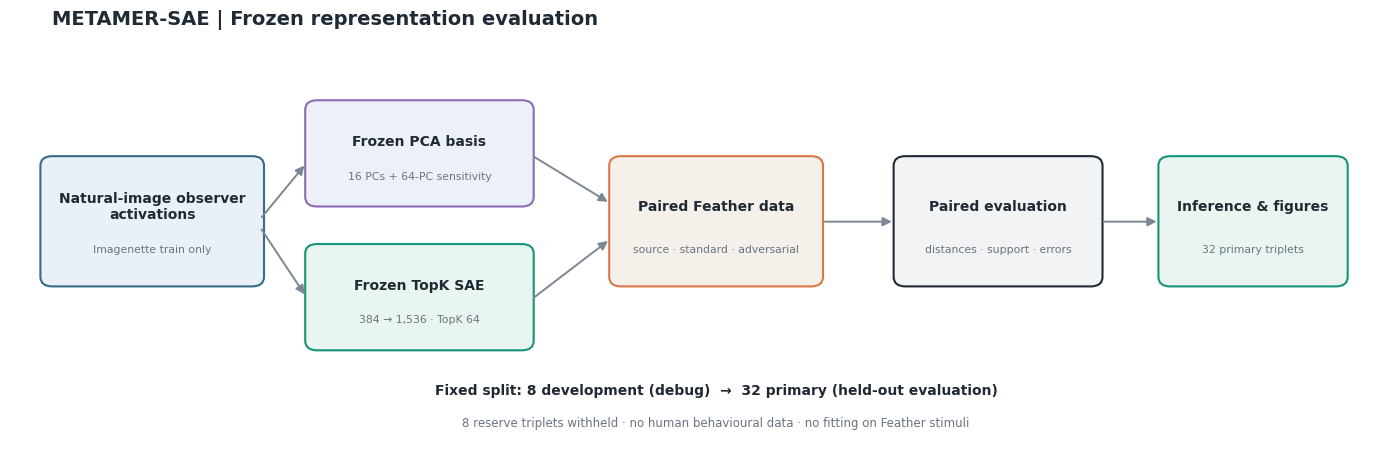

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.set_xlim(0, 14); ax.set_ylim(0, 5); ax.axis('off')

boxes = [
    (0.35, 2.05, 2.2, 1.55, 'Natural-image observer\nactivations', 'Imagenette train only', '#EAF1F6', COLORS['source']),
    (3.05, 3.05, 2.25, 1.25, 'Frozen PCA basis', '16 PCs + 64-PC sensitivity', '#EEF0F8', COLORS['pca_64']),
    (3.05, 1.25, 2.25, 1.25, 'Frozen TopK SAE', '384 → 1,536 · TopK 64', '#E8F5F1', COLORS['sae_seed123']),
    (6.15, 2.05, 2.1, 1.55, 'Paired Feather data', 'source · standard · adversarial', '#F5F1EA', COLORS['standard']),
    (9.05, 2.05, 2.05, 1.55, 'Paired evaluation', 'distances · support · errors', '#F1F3F5', COLORS['ink']),
    (11.75, 2.05, 1.85, 1.55, 'Inference & figures', '32 primary triplets', '#EAF5F1', COLORS['adversarial']),
]
for x,y,w,h,title,sub,face,edge in boxes:
    rect = patches.FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.04,rounding_size=0.12',
                                  linewidth=1.5,edgecolor=edge,facecolor=face)
    ax.add_patch(rect)
    ax.text(x+w/2,y+h*0.62,title,ha='center',va='center',fontsize=10,fontweight='bold')
    ax.text(x+w/2,y+h*0.27,sub,ha='center',va='center',fontsize=7.8,color=COLORS['muted'])

# Flow arrows
arrows = [((2.55,2.85),(3.02,3.55)),((2.55,2.75),(3.02,1.88)),
          ((5.32,3.65),(6.12,3.05)),((5.32,1.85),(6.12,2.60)),
          ((8.28,2.82),(9.02,2.82)),((11.12,2.82),(11.72,2.82))]
for a,b in arrows:
    ax.add_patch(patches.FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=13,
                                         linewidth=1.4,color='#7B8794'))
ax.text(7.2,0.65,'Fixed split: 8 development (debug)  →  32 primary (held-out evaluation)',
        ha='center',fontsize=10,fontweight='semibold',color=COLORS['ink'])
ax.text(7.2,0.25,'8 reserve triplets withheld · no human behavioural data · no fitting on Feather stimuli',
        ha='center',fontsize=8.5,color=COLORS['muted'])
fig.suptitle('METAMER-SAE | Frozen representation evaluation',x=0.04,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout()
save_figure(fig,'figure_01_evaluation_design')

### Figure 2 — Paired reconstruction error

Each panel is one frozen representation. Thin lines link source, standard and adversarial stimuli from the same triplet; overlaid points show individual samples. Read within each method first.

Saved: figure_02_paired_reconstruction_error.png | figure_02_paired_reconstruction_error.pdf


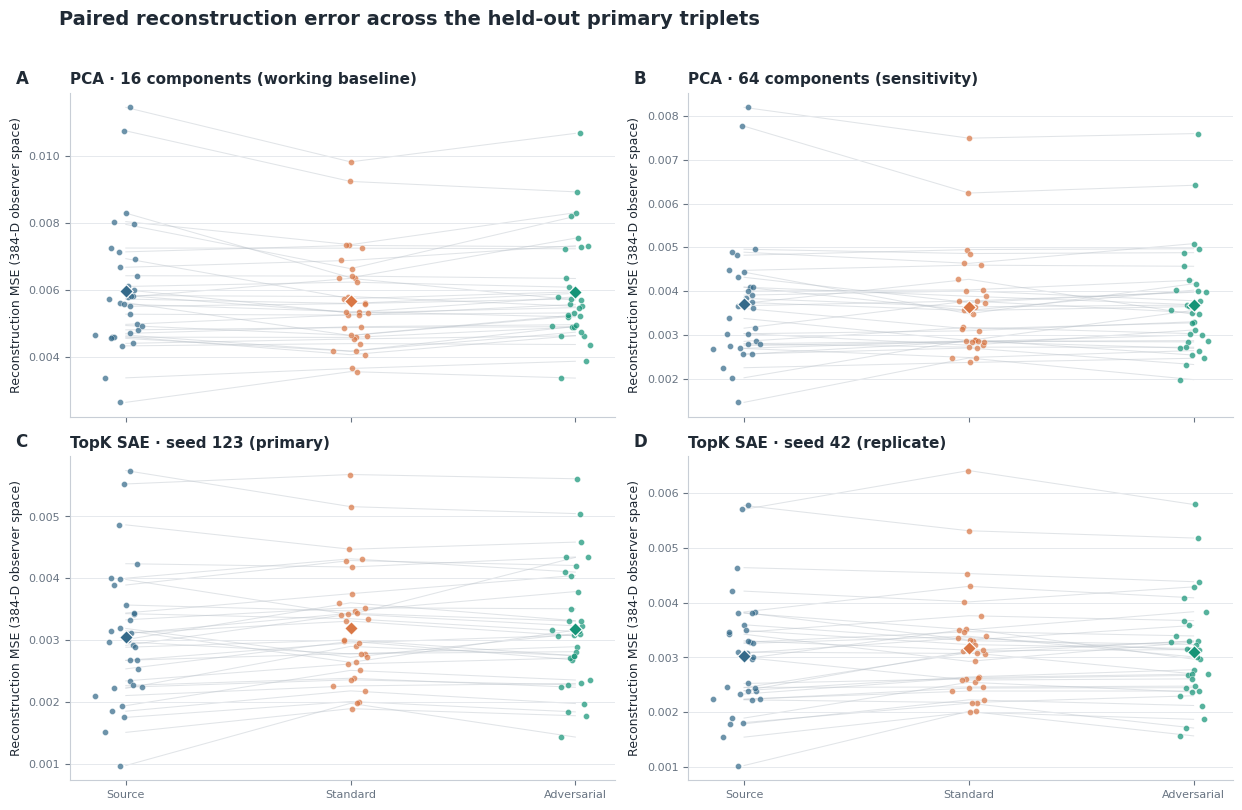

In [ ]:
methods_for_recon = ['pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']
method_titles = {
    'pca_16': 'PCA · 16 components (working baseline)',
    'pca_64': 'PCA · 64 components (sensitivity)',
    'sae_seed123': 'TopK SAE · seed 123 (primary)',
    'sae_seed42': 'TopK SAE · seed 42 (replicate)',
}
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), sharex=True)
for ax, method in zip(axes.flat, methods_for_recon):
    d = primary_stimulus_df[primary_stimulus_df.representation == method]
    wide = d.pivot(index='stimulus_id', columns='condition', values='reconstruction_mse').loc[split_ids['primary_evaluation']]
    x = np.arange(3)
    for _, row in wide.iterrows():
        ax.plot(x, row[['source','standard','adversarial']].values, color='#B8C0C8',
                alpha=0.42, linewidth=0.75, zorder=1)
    for j, cond in enumerate(['source','standard','adversarial']):
        vals = wide[cond].values
        jitter = np.random.default_rng(SEED+j).normal(0,0.045,len(vals))
        ax.scatter(np.full(len(vals),j)+jitter, vals, s=19, color=COLORS[cond],
                   alpha=0.72, edgecolor='white', linewidth=0.35, zorder=3)
        ax.scatter(j, np.mean(vals), marker='D', s=48, color=COLORS[cond],
                   edgecolor='white', linewidth=0.8, zorder=4)
    ax.set_title(method_titles[method],loc='left')
    ax.set_xticks(x, ['Source','Standard','Adversarial'])
    ax.set_ylabel('Reconstruction MSE (384-D observer space)')
    style_axis(ax)
    add_panel_label(ax, chr(65 + methods_for_recon.index(method)))
fig.suptitle('Paired reconstruction error across the held-out primary triplets',x=0.05,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout(rect=[0,0,1,0.96])
save_figure(fig,'figure_02_paired_reconstruction_error')

### Figure 3 — Standard-versus-adversarial source distance

Each dot is one source triplet. The x-axis is the source-to-standard distance; the y-axis is source-to-adversarial distance. Points below the diagonal indicate a smaller adversarial displacement for that triplet. The panels show each representation separately; raw magnitudes should not be compared across panels.

Saved: figure_03_paired_source_metamer_distances.png | figure_03_paired_source_metamer_distances.pdf


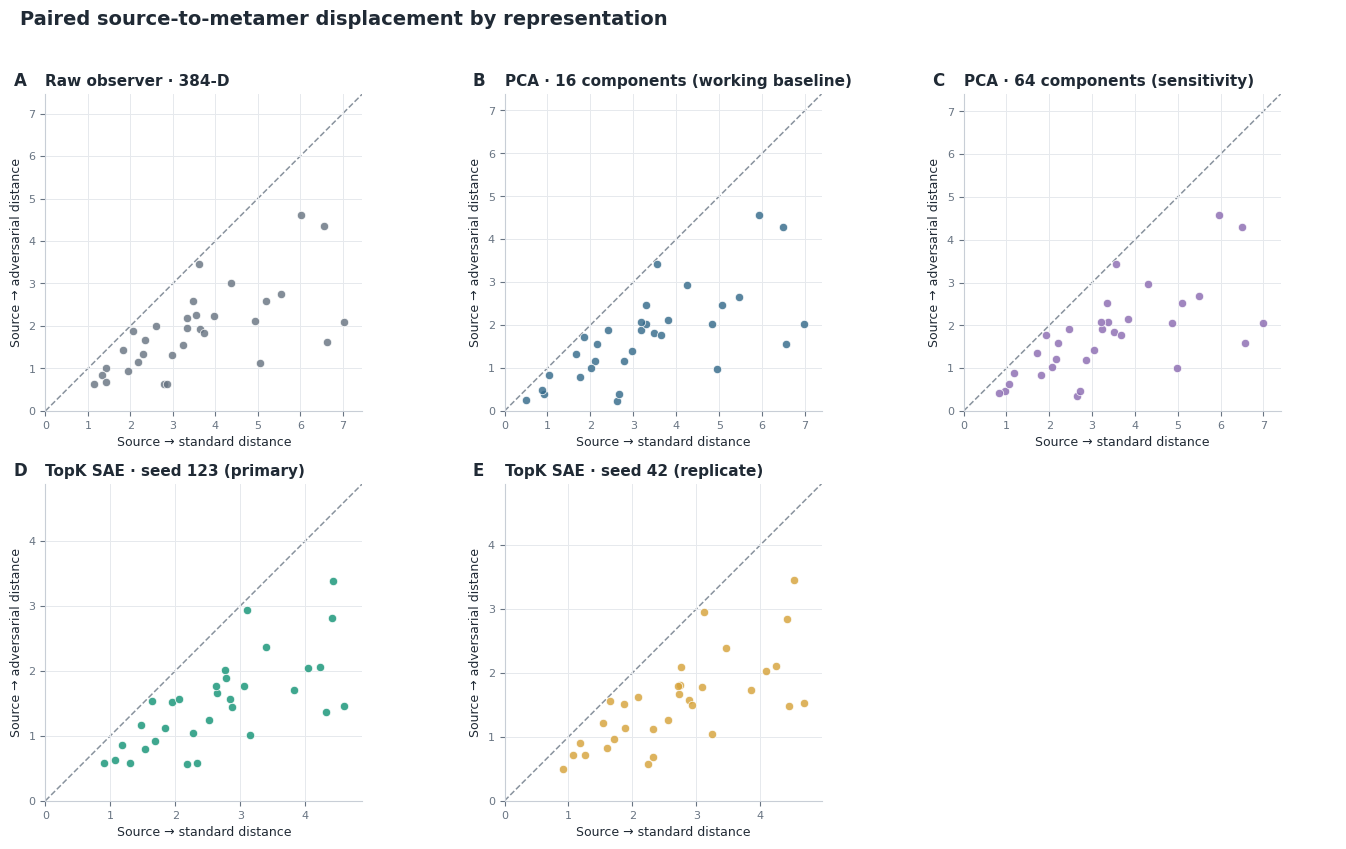

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.6))
plot_methods = ['raw_384','pca_16','pca_64','sae_seed123','sae_seed42']
for ax, method in zip(axes.flat, plot_methods):
    sub = primary_pair_df[primary_pair_df.representation == method]
    wide = sub.pivot(index='stimulus_id', columns='metamer_condition', values='distance_l2').loc[split_ids['primary_evaluation']]
    x, y = wide['standard'].values, wide['adversarial'].values
    lim = max(float(np.nanmax([x.max(),y.max()]))*1.06, 1e-6)
    ax.plot([0,lim],[0,lim],linestyle='--',color='#89939E',linewidth=1.1,zorder=1)
    ax.scatter(x,y,s=36,color=COLORS.get(method,COLORS['ink']),alpha=0.82,
               edgecolor='white',linewidth=0.6,zorder=3)
    ax.set_xlim(0,lim); ax.set_ylim(0,lim)
    ax.set_aspect('equal',adjustable='box')
    ax.set_title(method_titles.get(method, 'Raw observer · 384-D'),loc='left')
    ax.set_xlabel('Source → standard distance')
    ax.set_ylabel('Source → adversarial distance')
    style_axis(ax,'both')
    add_panel_label(ax, chr(65 + plot_methods.index(method)))
axes.flat[-1].axis('off')
fig.suptitle('Paired source-to-metamer displacement by representation',x=0.05,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout(rect=[0,0,1,0.96])
save_figure(fig,'figure_03_paired_source_metamer_distances')

### Figure 4 — Paired effect-size forest plot

The forest plot summarises the paired standard-minus-adversarial L2 distance contrast with triplet-bootstrap 95% confidence intervals. Positive values indicate greater source displacement for standard metamers. Cohen's *d*<sub>z</sub> is printed as a scale-free companion; the x-axis remains method-specific distance units.

Points show the mean paired difference (standard minus adversarial source distance); horizontal intervals are 95% triplet-bootstrap confidence intervals. Labels show paired Cohen's $d_z$. Positive values indicate greater standard-metamer displacement.

Saved: figure_04_paired_distance_effect_forest.png | figure_04_paired_distance_effect_forest.pdf


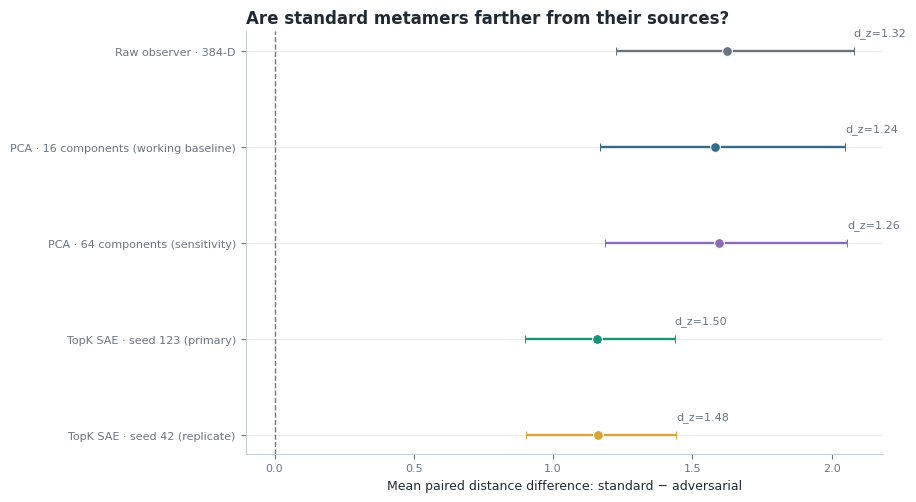

In [ ]:
forest_rows = []
for method in representations:
    sub = primary_pair_df[primary_pair_df.representation == method]
    wide = sub.pivot(index='stimulus_id', columns='metamer_condition', values='distance_l2').loc[split_ids['primary_evaluation']]
    diff = (wide['standard'] - wide['adversarial']).to_numpy(float)
    lo, hi = bootstrap_mean_ci(diff)
    sd = np.std(diff,ddof=1)
    forest_rows.append({'representation':method,'mean_difference':diff.mean(),
                        'ci_low':lo,'ci_high':hi,'cohens_dz':diff.mean()/sd if sd>0 else np.nan})
forest_df = pd.DataFrame(forest_rows)
forest_df.to_csv(TABLE_DIR / 'primary_distance_effect_forest.csv',index=False)

fig, ax = plt.subplots(figsize=(9.2,5.1))
y = np.arange(len(forest_df))[::-1]
for yi, row in zip(y, forest_df.to_dict('records')):
    method = row['representation']
    ax.errorbar(row['mean_difference'], yi,
                xerr=[[row['mean_difference']-row['ci_low']],[row['ci_high']-row['mean_difference']]],
                fmt='o',markersize=7,capsize=3,elinewidth=1.7,
                color=COLORS[method],markeredgecolor='white',markeredgewidth=0.7)
    ax.text(row['ci_high'], yi+0.16, f"d_z={row['cohens_dz']:.2f}",fontsize=8,color=COLORS['muted'])
ax.axvline(0,color='#697582',linestyle='--',linewidth=1)
ax.set_yticks(y, [method_titles.get(m,'Raw observer · 384-D') for m in forest_df.representation])
ax.set_xlabel('Mean paired distance difference: standard − adversarial')
ax.set_title('Are standard metamers farther from their sources?',loc='left',fontsize=12,fontweight='semibold')
style_axis(ax)
fig.tight_layout()
save_figure(fig,'figure_04_paired_distance_effect_forest')

### Figure 5 — PCA component displacement profiles

Mean absolute source-to-metamer component displacement, scaled by each component's training standard deviation. The first 16 PCs are the working baseline; the first 64 are shown as a sensitivity view. Component loadings are not assigned semantic labels.

Saved: figure_05_pca_component_displacement.png | figure_05_pca_component_displacement.pdf


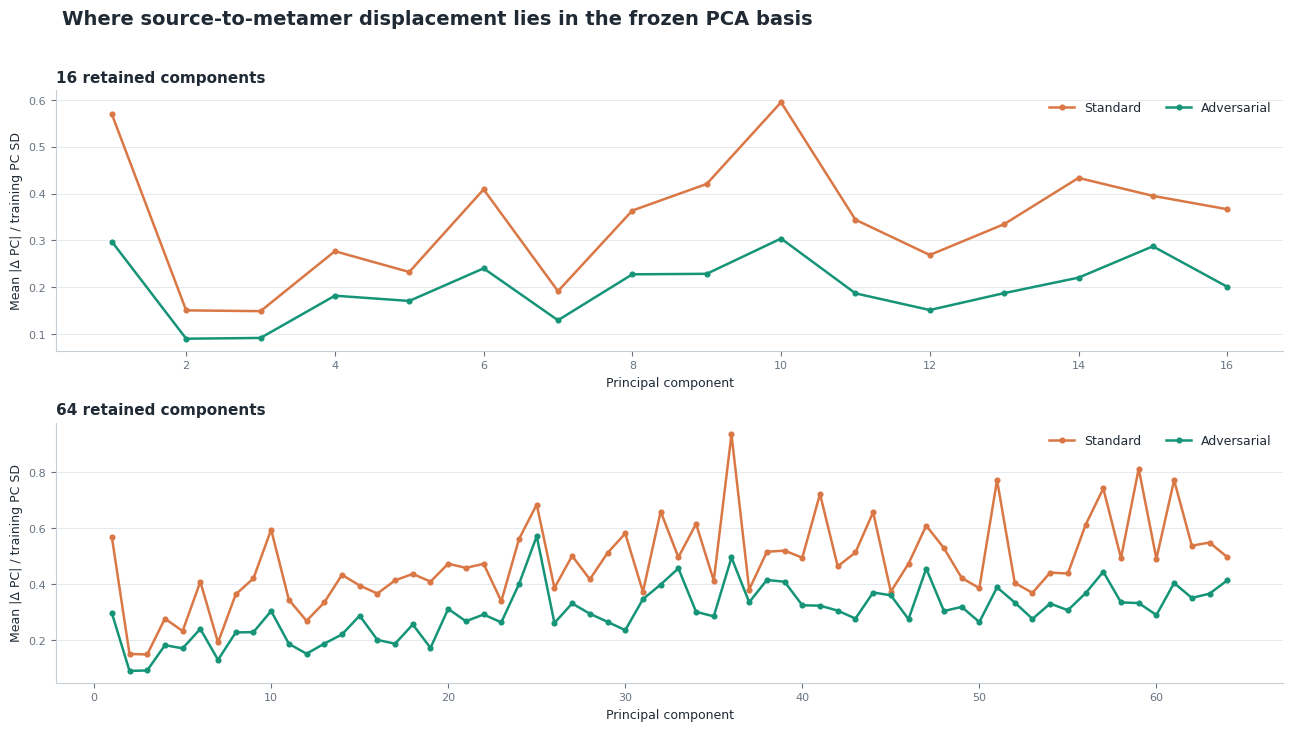

In [ ]:
fig, axes = plt.subplots(2,1,figsize=(13,7.4),sharex=False)
for ax, k, method in zip(axes,[16,64],['pca_16','pca_64']):
    d = pca_profile_df[(pca_profile_df.split=='primary_evaluation') & (pca_profile_df.representation==method)]
    for cond in ['standard','adversarial']:
        q = d[d.metamer_condition==cond].sort_values('component')
        ax.plot(q.component,q.mean_absolute_delta_pc_sd,marker='o',markersize=3.4,
                linewidth=1.8,color=COLORS[cond],label=cond.capitalize())
    ax.set_title(f'{k} retained components',loc='left')
    ax.set_ylabel('Mean |Δ PC| / training PC SD')
    ax.set_xlabel('Principal component')
    ax.legend(ncol=2)
    style_axis(ax)
fig.suptitle('Where source-to-metamer displacement lies in the frozen PCA basis',x=0.05,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout(rect=[0,0,1,0.96])
save_figure(fig,'figure_05_pca_component_displacement')

### Figure 6 — SAE feature-response atlas

The rows are the 40 features with the greatest total activation mass on the Imagenette training set (seed-123 dictionary only). Columns are the 32 held-out source images, followed by their paired standard and adversarial metamers in exactly the same triplet order. The second panel shows signed metamer-minus-source feature changes. The feature ranking is fixed using natural training data only.

Saved: figure_06_sae_feature_response_atlas_primary.png | figure_06_sae_feature_response_atlas_primary.pdf


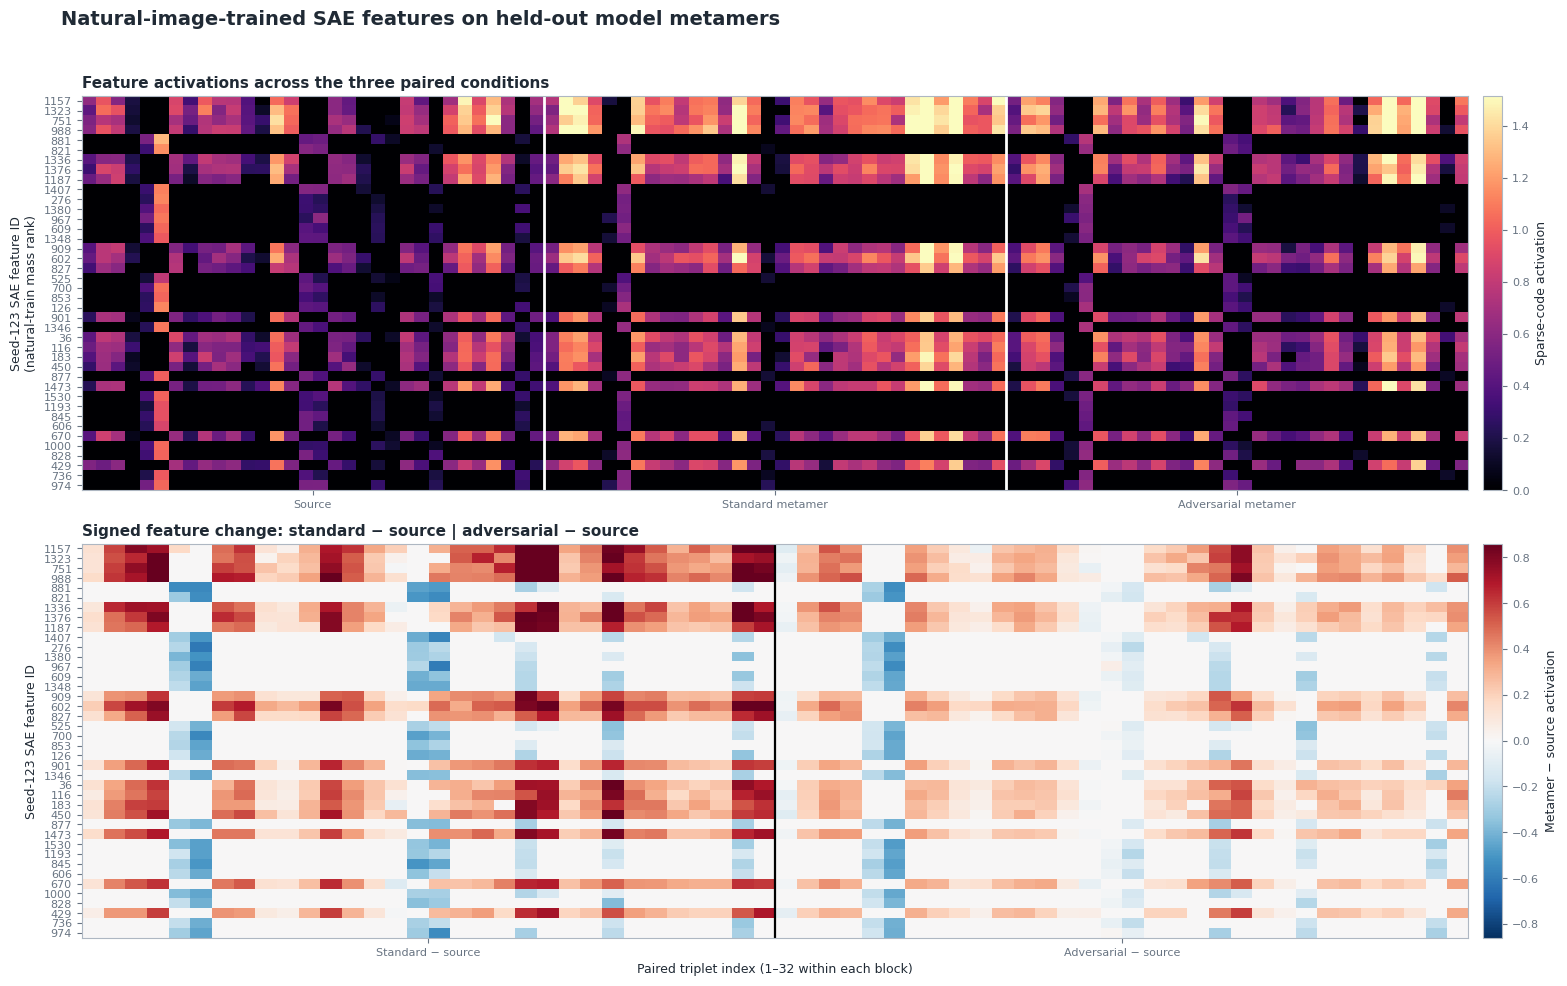

In [ ]:
codes_primary = primary_result['sae_codes']['seed123']
source_codes = codes_primary['source']
standard_codes = codes_primary['standard']
adversarial_codes = codes_primary['adversarial']
feature_ids = top_natural_feature_ids

activation_heat = np.concatenate([source_codes,standard_codes,adversarial_codes],axis=0)[:,feature_ids].T
all_delta = np.concatenate([standard_codes-source_codes,adversarial_codes-source_codes],axis=0)[:,feature_ids].T
vmax = float(np.quantile(activation_heat,0.99))
dlim = float(np.quantile(np.abs(all_delta),0.99))
if dlim <= 0: dlim = 1.0

fig, axes = plt.subplots(2,1,figsize=(16,10),gridspec_kw={'height_ratios':[1,1]})
im0 = axes[0].imshow(activation_heat,aspect='auto',interpolation='nearest',cmap='magma',vmin=0,vmax=vmax)
axes[0].axvline(31.5,color='white',linewidth=2)
axes[0].axvline(63.5,color='white',linewidth=2)
axes[0].set_yticks(np.arange(len(feature_ids)),[str(x) for x in feature_ids])
axes[0].set_ylabel('Seed-123 SAE feature ID\n(natural-train mass rank)')
axes[0].set_title('Feature activations across the three paired conditions',loc='left')
axes[0].set_xticks([15.5,47.5,79.5],['Source','Standard metamer','Adversarial metamer'])
cb0=fig.colorbar(im0,ax=axes[0],fraction=0.018,pad=0.01); cb0.set_label('Sparse-code activation')
im1 = axes[1].imshow(all_delta,aspect='auto',interpolation='nearest',cmap='RdBu_r',
                      norm=TwoSlopeNorm(vmin=-dlim,vcenter=0,vmax=dlim))
axes[1].axvline(31.5,color='black',linewidth=1.6)
axes[1].set_yticks(np.arange(len(feature_ids)),[str(x) for x in feature_ids])
axes[1].set_ylabel('Seed-123 SAE feature ID')
axes[1].set_xlabel('Paired triplet index (1–32 within each block)')
axes[1].set_title('Signed feature change: standard − source | adversarial − source',loc='left')
axes[1].set_xticks([15.5,47.5],['Standard − source','Adversarial − source'])
cb1=fig.colorbar(im1,ax=axes[1],fraction=0.018,pad=0.01); cb1.set_label('Metamer − source activation')
fig.suptitle('Natural-image-trained SAE features on held-out model metamers',x=0.04,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout(rect=[0,0,0.985,0.96])
save_figure(fig,'figure_06_sae_feature_response_atlas_primary')

### Figure 7 — Feature-wise standard/adversarial change comparison

Each point is one seed-123 SAE feature. The axes show the mean absolute feature change from source for standard and adversarial metamers across the 32 paired triplets. The colour encodes the feature's activation mass on natural Imagenette training images. This is descriptive and does not establish feature semantics or causal importance.

Each point is one seed-123 dictionary feature. This is a descriptive comparison across feature indices within the same SAE only; it is not a statistical test across independent samples and does not establish semantic or causal feature roles.

Saved: figure_07_feature_change_standard_vs_adversarial.png | figure_07_feature_change_standard_vs_adversarial.pdf


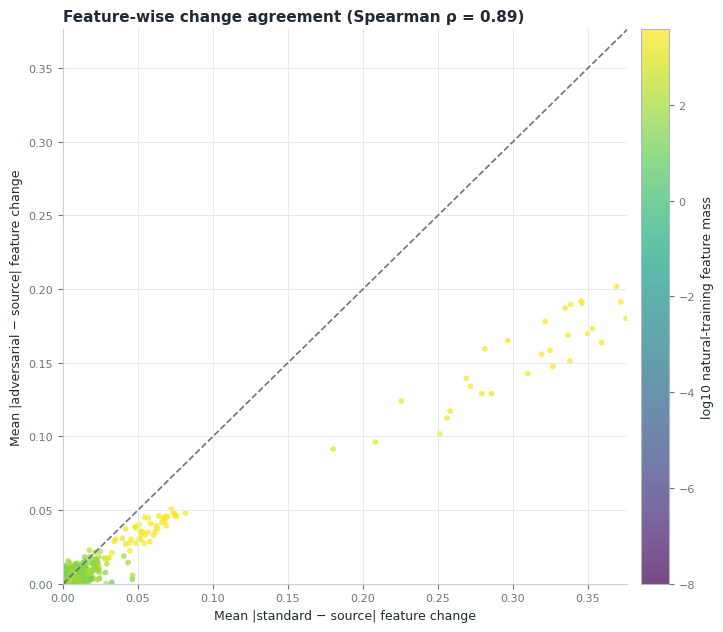

In [ ]:
feat_std = feature_summaries[('primary_evaluation','seed123')]
feat_std = feat_std[feat_std.metamer_condition=='standard'].set_index('feature_id')
feat_adv = feature_summaries[('primary_evaluation','seed123')]
feat_adv = feat_adv[feat_adv.metamer_condition=='adversarial'].set_index('feature_id')

x = feat_std.loc[np.arange(DICT_WIDTH),'mean_absolute_change'].to_numpy()
y = feat_adv.loc[np.arange(DICT_WIDTH),'mean_absolute_change'].to_numpy()
colour = np.log10(natural_train_mass + 1e-8)
lim = max(float(np.quantile(np.concatenate([x,y]),0.995))*1.08,1e-8)
rho = stats.spearmanr(x,y).statistic

fig, ax = plt.subplots(figsize=(7.6,6.4))
sc=ax.scatter(x,y,c=colour,cmap='viridis',s=17,alpha=0.72,edgecolor='none')
ax.plot([0,lim],[0,lim],linestyle='--',linewidth=1.2,color='#6B7280')
ax.set_xlim(0,lim); ax.set_ylim(0,lim)
ax.set_xlabel('Mean |standard − source| feature change')
ax.set_ylabel('Mean |adversarial − source| feature change')
ax.set_title(f'Feature-wise change agreement (Spearman ρ = {rho:.2f})',loc='left')
cb=fig.colorbar(sc,ax=ax,pad=0.02); cb.set_label('log10 natural-training feature mass')
style_axis(ax,'both')
fig.tight_layout()
save_figure(fig,'figure_07_feature_change_standard_vs_adversarial')

### Figure 8 — Raw observer spatial-difference maps

The two maps show the mean absolute raw observer activation difference between each metamer and its paired source, averaged across channels and the 32 primary triplets. They are included as a supplementary spatial diagnostic because global pooling discards location. The maps are not SAE feature maps and are not causal attributions.

These are raw ConvNeXt observer activation differences averaged over channels and triplets. They are not spatial SAE feature maps.

/tmp/ipykernel_425/1283774763.py:11: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0,0,0.93,0.92])


Saved: figure_08_raw_observer_spatial_difference_maps.png | figure_08_raw_observer_spatial_difference_maps.pdf


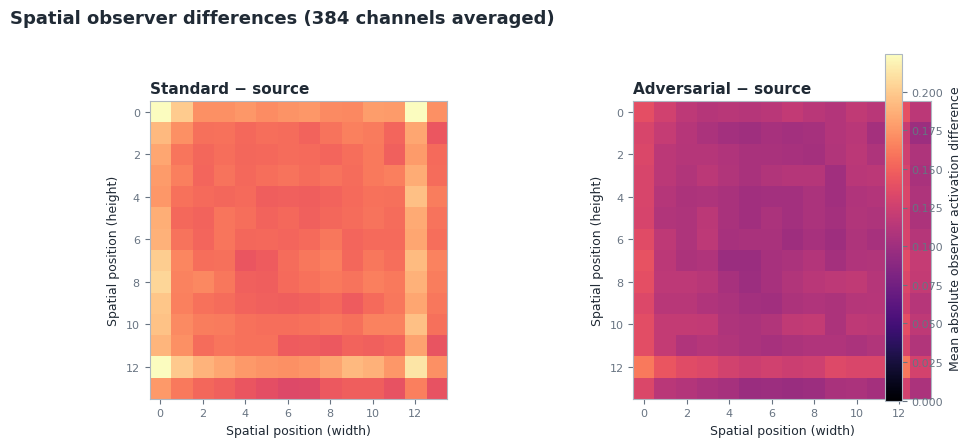

In [ ]:
if ('primary_evaluation','standard') in spatial_mean_maps:
    fig, axes = plt.subplots(1,2,figsize=(10.5,4.5))
    vmax = max(float(np.quantile(spatial_mean_maps[('primary_evaluation','standard')],0.99)),
               float(np.quantile(spatial_mean_maps[('primary_evaluation','adversarial')],0.99)))
    for ax, cond in zip(axes,['standard','adversarial']):
        im=ax.imshow(spatial_mean_maps[('primary_evaluation',cond)],cmap='magma',origin='upper',vmin=0,vmax=vmax)
        ax.set_title(f'{cond.capitalize()} − source',loc='left')
        ax.set_xlabel('Spatial position (width)'); ax.set_ylabel('Spatial position (height)')
    cb=fig.colorbar(im,ax=axes.ravel().tolist(),fraction=0.035,pad=0.03); cb.set_label('Mean absolute observer activation difference')
    fig.suptitle('Spatial observer differences (384 channels averaged)',x=0.04,ha='left',fontsize=13,fontweight='bold')
    fig.tight_layout(rect=[0,0,0.93,0.92])
    save_figure(fig,'figure_08_raw_observer_spatial_difference_maps')
else:
    print("Figure 08 skipped: spatial maps were not created.")

### Figure 9 — Paired image examples

A small, predetermined sample of the primary split is shown as source / standard / adversarial triplets. These are illustrative stimuli, not selected as representative examples by their measured scores. If the metadata-relative image paths are unavailable in the current Drive layout, this figure is skipped without interrupting the quantitative evaluation.

Saved: figure_09_primary_triplet_examples.png | figure_09_primary_triplet_examples.pdf


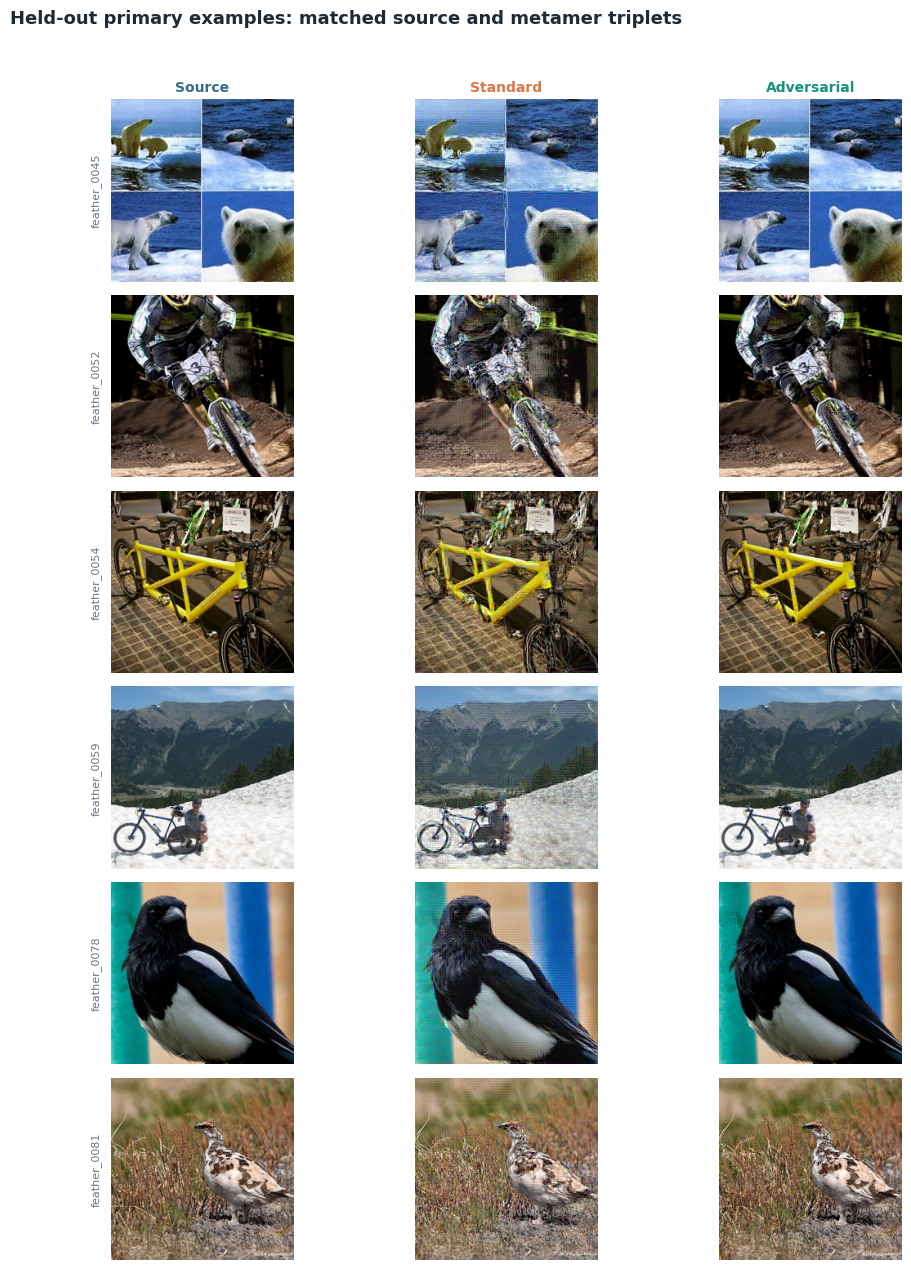

In [ ]:
def resolve_relative_image_path(value):
    if not isinstance(value,str) or not value.strip() or value.lower()=='nan':
        return None
    p=Path(value)
    candidates=[p] if p.is_absolute() else [PROJECT_ROOT/p, PROJECT_ROOT/'stimuli'/p]
    # Older manifest paths may start with 'stimuli/' while the project root itself is mounted differently.
    for candidate in candidates:
        if candidate.exists(): return candidate
    return None

if MAKE_PRIMARY_IMAGE_GALLERY and all(c in metadata_path_maps for c in ('source','standard','adversarial')):
    example_ids=split_ids['primary_evaluation'][:6]
    resolved={}
    for sid in example_ids:
        resolved[sid]={}
        for cond in ('source','standard','adversarial'):
            resolved[sid][cond]=resolve_relative_image_path(metadata_path_maps[cond].get(sid))
    available=all(path is not None for row in resolved.values() for path in row.values())
    if available:
        fig,axes=plt.subplots(len(example_ids),3,figsize=(10.5,2.15*len(example_ids)))
        for i,sid in enumerate(example_ids):
            for j,cond in enumerate(('source','standard','adversarial')):
                ax=axes[i,j]
                with Image.open(resolved[sid][cond]) as im:
                    ax.imshow(im.convert('RGB'))
                ax.axis('off')
                if i==0: ax.set_title(cond.capitalize(),fontsize=10,fontweight='bold',color=COLORS[cond])
                if j==0: ax.text(-0.08,0.5,sid,transform=ax.transAxes,rotation=90,ha='center',va='center',fontsize=8,color=COLORS['muted'])
        fig.suptitle('Held-out primary examples: matched source and metamer triplets',x=0.04,ha='left',fontsize=13,fontweight='bold')
        fig.tight_layout(rect=[0.025,0,1,0.96])
        save_figure(fig,'figure_09_primary_triplet_examples')
    else:
        print("Image gallery skipped; at least one metadata-relative image path could not be resolved.")
else:
    print("Image gallery skipped; metadata relative paths are unavailable or gallery disabled.")

### Figure 10 — Consolidated primary-evaluation dashboard

A paper-style dashboard consolidating paired representation displacement, reconstruction error, active-support overlap and paired standard/adversarial distance effects. Each panel retains its own measurement scale.

Saved: figure_10_primary_results_dashboard.png | figure_10_primary_results_dashboard.pdf


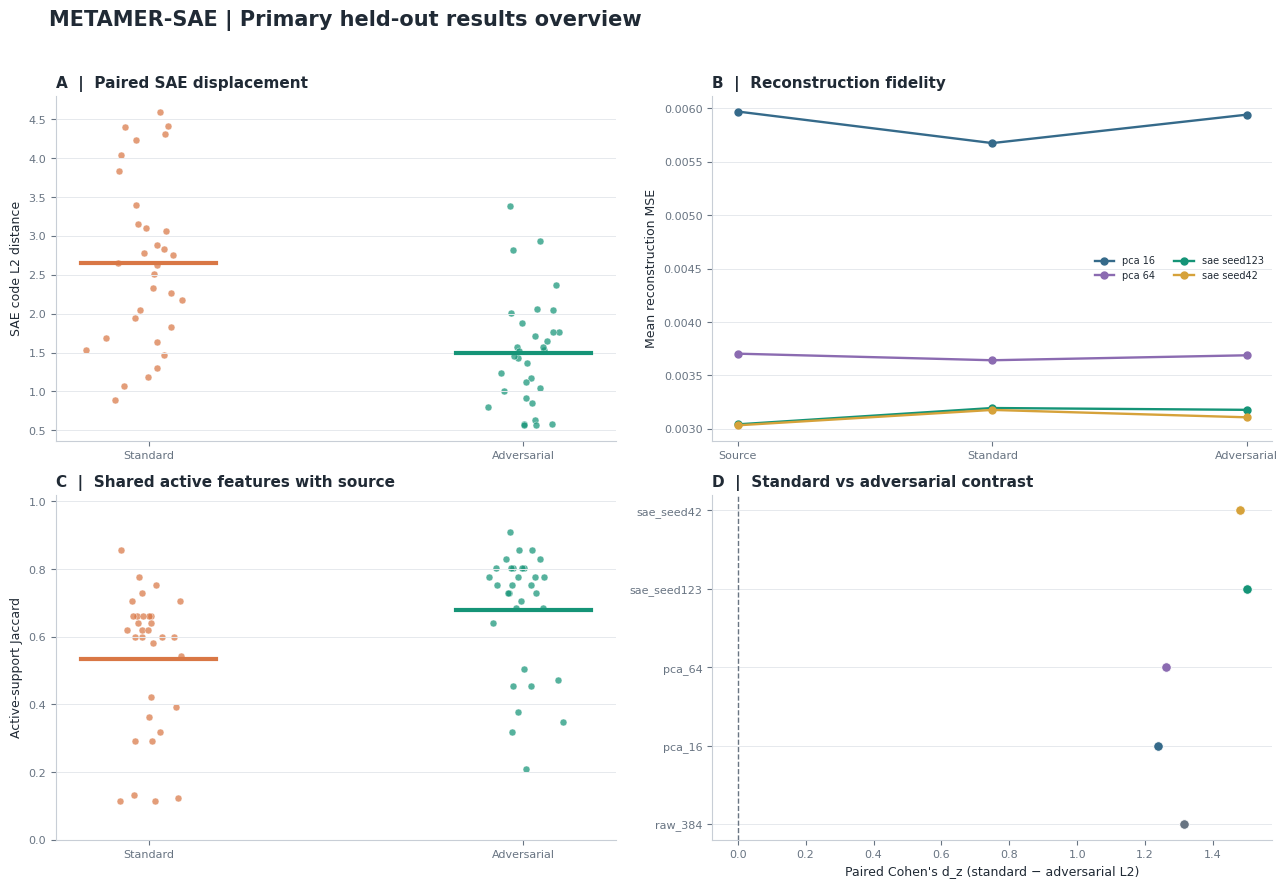

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(13,9))

# A: paired SAE code distances
ax=axes[0,0]
sub=primary_pair_df[primary_pair_df.representation=='sae_seed123']
for i,cond in enumerate(['standard','adversarial']):
    vals=sub[sub.metamer_condition==cond].distance_l2.to_numpy()
    jitter=np.random.default_rng(SEED+i).normal(0,0.055,len(vals))
    ax.scatter(np.full(len(vals),i)+jitter,vals,s=25,color=COLORS[cond],alpha=0.72,edgecolor='white',linewidth=0.4)
    ax.plot([i-0.18,i+0.18],[vals.mean(),vals.mean()],color=COLORS[cond],linewidth=3)
ax.set_xticks([0,1],['Standard','Adversarial']); ax.set_ylabel('SAE code L2 distance')
ax.set_title('A  |  Paired SAE displacement',loc='left'); style_axis(ax)

# B: reconstruction MSE by method and condition (mean)
ax=axes[0,1]
q=reconstruction_summary[reconstruction_summary.representation.isin(methods_for_recon)]
for m in methods_for_recon:
    vals=[]
    for cond in ['source','standard','adversarial']:
        vals.append(float(q[(q.representation==m)&(q.condition==cond)].mean_mse.iloc[0]))
    ax.plot([0,1,2],vals,marker='o',linewidth=1.7,markersize=5,color=COLORS[m],label=m.replace('_',' '))
ax.set_xticks([0,1,2],['Source','Standard','Adversarial']); ax.set_ylabel('Mean reconstruction MSE')
ax.set_title('B  |  Reconstruction fidelity',loc='left'); ax.legend(fontsize=7,ncol=2); style_axis(ax)

# C: SAE active support overlap
ax=axes[1,0]
for i,cond in enumerate(['standard','adversarial']):
    vals=primary_pair_df[(primary_pair_df.representation=='sae_seed123')&(primary_pair_df.metamer_condition==cond)].support_jaccard.to_numpy()
    jitter=np.random.default_rng(SEED+10+i).normal(0,0.045,len(vals))
    ax.scatter(np.full(len(vals),i)+jitter,vals,s=25,color=COLORS[cond],alpha=0.72,edgecolor='white',linewidth=0.4)
    ax.plot([i-0.18,i+0.18],[np.mean(vals),np.mean(vals)],color=COLORS[cond],linewidth=3)
ax.set_xticks([0,1],['Standard','Adversarial']); ax.set_ylim(0,1.02); ax.set_ylabel('Active-support Jaccard')
ax.set_title('C  |  Shared active features with source',loc='left'); style_axis(ax)

# D: effect size overview
ax=axes[1,1]
for j,row in forest_df.iterrows():
    ax.scatter(row.cohens_dz,j,s=48,color=COLORS[row.representation],edgecolor='white',linewidth=0.7,zorder=3)
ax.axvline(0,color='#697582',linestyle='--',linewidth=1)
ax.set_yticks(np.arange(len(forest_df)),forest_df.representation)
ax.set_xlabel("Paired Cohen's d_z (standard − adversarial L2)")
ax.set_title('D  |  Standard vs adversarial contrast',loc='left'); style_axis(ax)

fig.suptitle('METAMER-SAE | Primary held-out results overview',x=0.04,ha='left',fontsize=15,fontweight='bold')
fig.tight_layout(rect=[0,0,1,0.96])
save_figure(fig,'figure_10_primary_results_dashboard')

## 13B. Additional paired-estimation visualisations

These supplementary figures are designed to make the primary results easier to inspect at the **triplet level**, rather than relying only on condition means or summary bars.

- **Figure 11:** paired relative-displacement profiles. Each line connects the standard and adversarial metamer generated from the same source triplet. Each panel is one representation; axes are intentionally independent across representations because their coordinate scales differ.
- **Figure 12:** a forest plot of the paired standard-minus-adversarial difference in source-normalised L2 displacement. It reports triplet-bootstrap 95% intervals and paired effect sizes. Positive values indicate greater displacement for standard metamers.
- **Figure 13:** paired reconstruction-error changes. Each point is one triplet's metamer-minus-source MSE difference; the vertical interval is a triplet-bootstrap 95% CI for the mean. The zero line means equal reconstruction error.
- **Figure 14:** feature-change ECDFs for the two SAE seeds. This compares distributions of per-feature mean absolute changes without assuming that feature IDs correspond across independently trained dictionaries.

All figures use Matplotlib only (no Seaborn), preserve the fixed primary split, and export 300-DPI PNG plus vector PDF. These are additional figures; existing figures and quantitative outputs are retained.

### Figure 11 — Triplet-level relative displacement

Saved: figure_11_paired_relative_displacement_profiles.png | figure_11_paired_relative_displacement_profiles.pdf


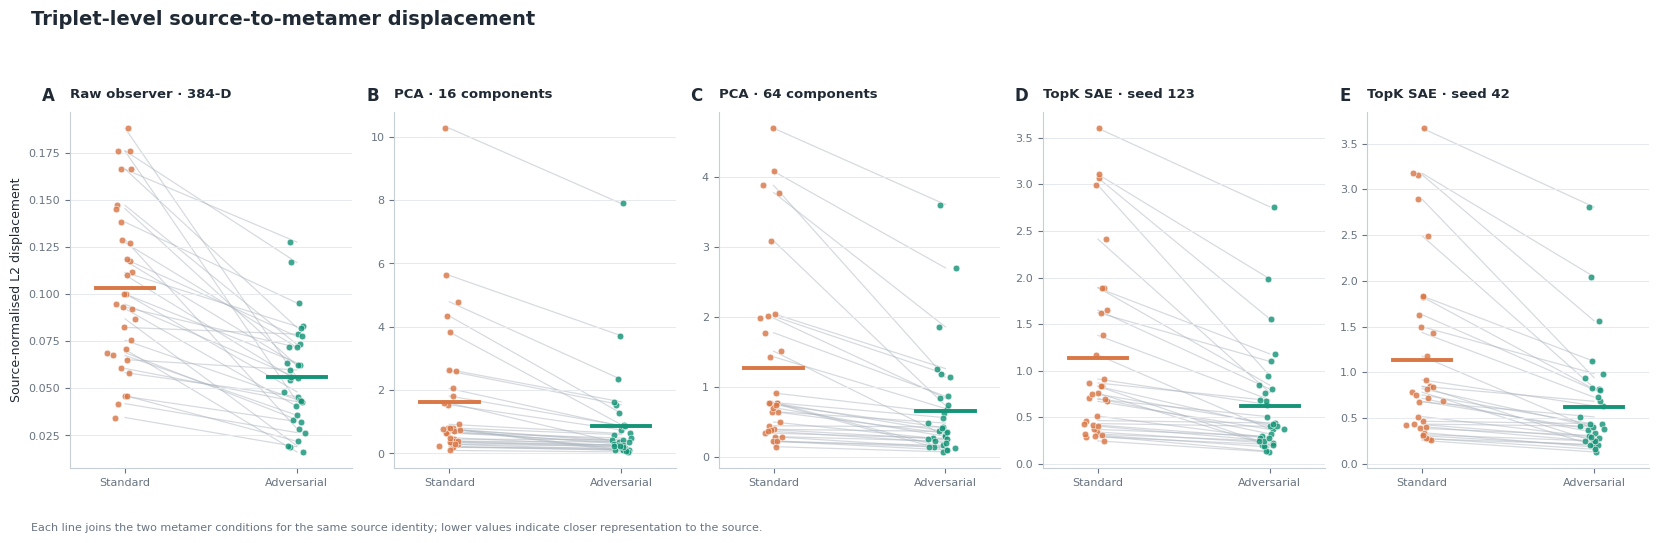

In [ ]:
# Figure 11 — paired triplet-level relative displacement profiles
# Relative L2 is normalised by each source activation/code norm, allowing
# within-representation paired comparisons without comparing raw scales
# across different representation spaces.
plot_methods = ['raw_384', 'pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']
plot_labels = {
    'raw_384': 'Raw observer · 384-D',
    'pca_16': 'PCA · 16 components',
    'pca_64': 'PCA · 64 components',
    'sae_seed123': 'TopK SAE · seed 123',
    'sae_seed42': 'TopK SAE · seed 42',
}

fig, axes = plt.subplots(1, 5, figsize=(17, 5.4), sharey=False)
for idx, (ax, method) in enumerate(zip(axes, plot_methods)):
    sub = primary_pair_df[primary_pair_df.representation == method]
    wide = sub.pivot(index='stimulus_id', columns='metamer_condition',
                     values='relative_l2_source_norm').loc[split_ids['primary_evaluation']]
    # Plot each source-matched triplet as a thin paired line.
    for _, row in wide.iterrows():
        ax.plot([0, 1], [row['standard'], row['adversarial']],
                color='#AAB3BD', alpha=0.48, linewidth=0.9, zorder=1)
    # Overlay individual observations with deterministic horizontal jitter.
    rng = np.random.default_rng(SEED + idx)
    for x_pos, condition in enumerate(['standard', 'adversarial']):
        vals = wide[condition].to_numpy(float)
        jitter = rng.normal(0, 0.035, size=len(vals))
        ax.scatter(np.full(len(vals), x_pos) + jitter, vals,
                   s=23, color=COLORS[condition], alpha=0.82,
                   edgecolor='white', linewidth=0.45, zorder=3)
        mean = float(np.mean(vals))
        ax.plot([x_pos - 0.17, x_pos + 0.17], [mean, mean],
                color=COLORS[condition], linewidth=2.8, zorder=4)
    ax.set_xticks([0, 1], ['Standard', 'Adversarial'])
    ax.set_title(plot_labels[method], loc='left', fontsize=9.5, pad=10)
    ax.set_xlim(-0.32, 1.32)
    ax.set_ylabel('Source-normalised L2 displacement' if idx == 0 else '')
    style_axis(ax, 'y')
    add_panel_label(ax, chr(65 + idx))

fig.suptitle('Triplet-level source-to-metamer displacement',
             x=0.04, ha='left', fontsize=14, fontweight='bold')
fig.text(0.04, 0.015,
         'Each line joins the two metamer conditions for the same source identity; lower values indicate closer representation to the source.',
         fontsize=8, color=COLORS['muted'])
fig.tight_layout(rect=[0.02, 0.07, 1, 0.93], w_pad=1.2)
save_figure(fig, 'figure_11_paired_relative_displacement_profiles')

### Figure 12 — Paired relative-displacement estimation plot

Saved: figure_12_relative_displacement_estimation_plot.png | figure_12_relative_displacement_estimation_plot.pdf


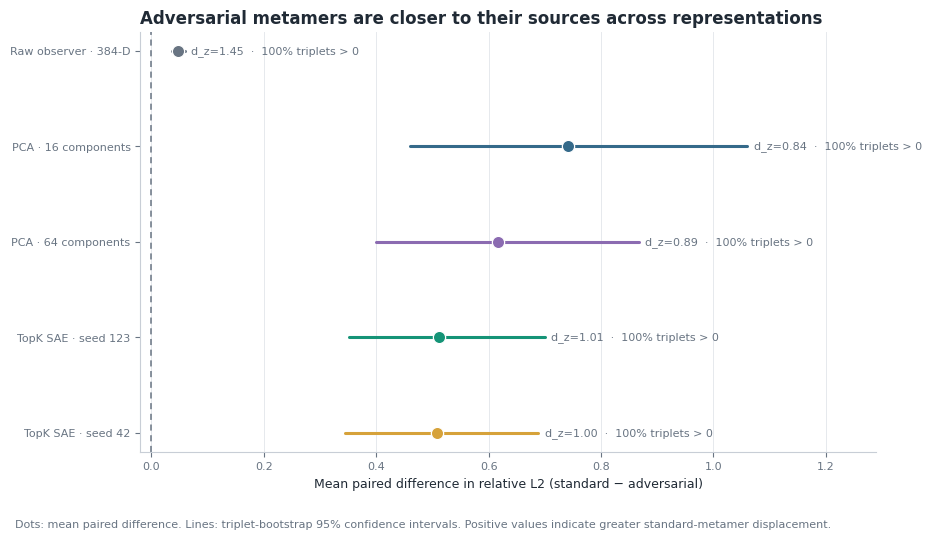

In [ ]:
# Figure 12 — estimation plot for paired relative-displacement contrasts
# Difference is standard minus adversarial; positive values favour closer
# source alignment for adversarial metamers.
relative_forest_rows = []
for method in representations:
    sub = primary_pair_df[primary_pair_df.representation == method]
    wide = sub.pivot(index='stimulus_id', columns='metamer_condition',
                     values='relative_l2_source_norm').loc[split_ids['primary_evaluation']]
    diff = (wide['standard'] - wide['adversarial']).to_numpy(float)
    lo, hi = bootstrap_mean_ci(diff, seed=BOOTSTRAP_SEED + representations.index(method))
    sd = float(np.std(diff, ddof=1))
    relative_forest_rows.append({
        'representation': method, 'n_triplets': len(diff),
        'mean_difference': float(np.mean(diff)),
        'median_difference': float(np.median(diff)),
        'ci_low': lo, 'ci_high': hi,
        'cohens_dz': float(np.mean(diff) / sd) if sd > 0 else np.nan,
        'fraction_positive': float(np.mean(diff > 0)),
    })
relative_forest_df = pd.DataFrame(relative_forest_rows)
relative_forest_df.to_csv(TABLE_DIR / 'primary_relative_distance_effect_forest.csv', index=False)

fig, ax = plt.subplots(figsize=(9.4, 5.4))
ypos = np.arange(len(relative_forest_df))[::-1]
for y, row in zip(ypos, relative_forest_df.to_dict('records')):
    colour = COLORS[row['representation']]
    ax.plot([row['ci_low'], row['ci_high']], [y, y],
            color=colour, linewidth=2.2, solid_capstyle='round', zorder=2)
    ax.scatter(row['mean_difference'], y, s=78, color=colour,
               edgecolor='white', linewidth=0.9, zorder=3)
    ax.text(row['ci_high'] + 0.012, y,
            f"d_z={row['cohens_dz']:.2f}  ·  {row['fraction_positive']:.0%} triplets > 0",
            va='center', fontsize=8, color=COLORS['muted'])
ax.axvline(0, color='#687482', linestyle=(0, (4, 3)), linewidth=1.1)
ax.set_yticks(ypos, [plot_labels[m] for m in relative_forest_df.representation])
ax.set_xlabel('Mean paired difference in relative L2 (standard − adversarial)')
ax.set_title('Adversarial metamers are closer to their sources across representations',
             loc='left', fontsize=12, fontweight='semibold')
ax.set_xlim(min(-0.02, relative_forest_df.ci_low.min() - 0.03),
            relative_forest_df.ci_high.max() + 0.23)
style_axis(ax, 'x')
fig.text(0.02, 0.015,
         'Dots: mean paired difference. Lines: triplet-bootstrap 95% confidence intervals. Positive values indicate greater standard-metamer displacement.',
         fontsize=8, color=COLORS['muted'])
fig.tight_layout(rect=[0, 0.06, 1, 1])
save_figure(fig, 'figure_12_relative_displacement_estimation_plot')

### Figure 13 — Paired reconstruction-error changes

Saved: figure_13_paired_reconstruction_error_changes.png | figure_13_paired_reconstruction_error_changes.pdf


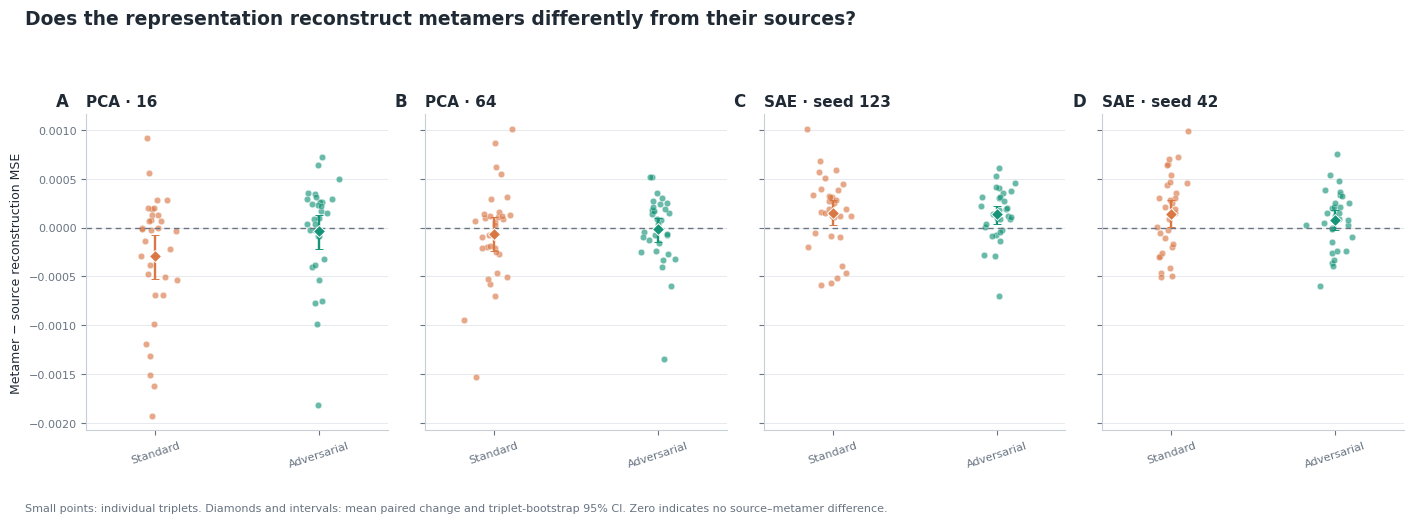

In [ ]:
# Figure 13 — triplet-level reconstruction-error changes
# Delta MSE = metamer reconstruction MSE - paired source reconstruction MSE.
# Positive values mean the metamer is less well reconstructed than its source.
recon_plot_methods = ['pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']
recon_plot_labels = {
    'pca_16': 'PCA · 16',
    'pca_64': 'PCA · 64',
    'sae_seed123': 'SAE · seed 123',
    'sae_seed42': 'SAE · seed 42',
}

fig, axes = plt.subplots(1, 4, figsize=(14.5, 5.2), sharey=True)
for idx, (ax, method) in enumerate(zip(axes, recon_plot_methods)):
    sub = primary_pair_df[primary_pair_df.representation == method]
    for x_pos, condition in enumerate(['standard', 'adversarial']):
        vals = sub[sub.metamer_condition == condition]['delta_reconstruction_error'].to_numpy(float)
        vals = vals[np.isfinite(vals)]
        rng = np.random.default_rng(SEED + 100 + idx * 3 + x_pos)
        jitter = rng.normal(0, 0.055, size=len(vals))
        ax.scatter(np.full(len(vals), x_pos) + jitter, vals,
                   s=22, color=COLORS[condition], alpha=0.64,
                   edgecolor='white', linewidth=0.35, zorder=2)
        lo, hi = bootstrap_mean_ci(vals, seed=BOOTSTRAP_SEED + idx * 5 + x_pos)
        mean = float(np.mean(vals))
        ax.errorbar(x_pos, mean, yerr=[[mean - lo], [hi - mean]],
                    fmt='D', markersize=6, color=COLORS[condition],
                    markeredgecolor='white', markeredgewidth=0.7,
                    capsize=3, elinewidth=1.7, zorder=4)
    ax.axhline(0, color='#687482', linestyle=(0, (4, 3)), linewidth=1)
    ax.set_xticks([0, 1], ['Standard', 'Adversarial'], rotation=18)
    ax.set_title(recon_plot_labels[method], loc='left')
    ax.set_xlim(-0.42, 1.42)
    ax.set_ylabel('Metamer − source reconstruction MSE' if idx == 0 else '')
    style_axis(ax, 'y')
    add_panel_label(ax, chr(65 + idx))

fig.suptitle('Does the representation reconstruct metamers differently from their sources?',
             x=0.04, ha='left', fontsize=13.5, fontweight='bold')
fig.text(0.04, 0.015,
         'Small points: individual triplets. Diamonds and intervals: mean paired change and triplet-bootstrap 95% CI. Zero indicates no source–metamer difference.',
         fontsize=8, color=COLORS['muted'])
fig.tight_layout(rect=[0.02, 0.07, 1, 0.92], w_pad=1.0)
save_figure(fig, 'figure_13_paired_reconstruction_error_changes')

### Figure 14 — SAE feature-change distributions

Saved: figure_14_sae_feature_change_ecdf.png | figure_14_sae_feature_change_ecdf.pdf


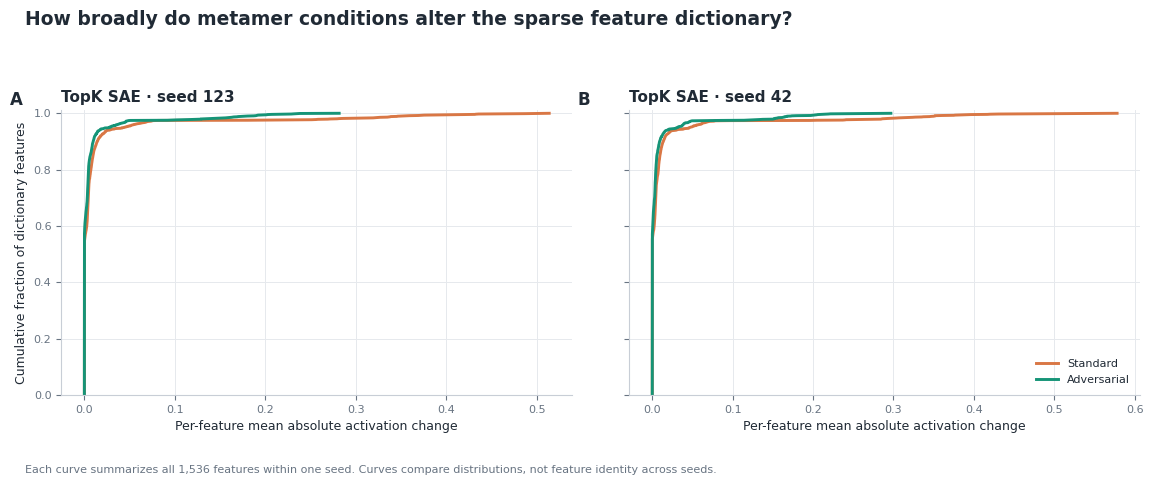

In [ ]:
# Figure 14 — feature-change distribution across the two independently trained SAEs
# ECDFs compare per-feature mean absolute activation change. Feature indices are
# never matched across seeds; each panel is analysed within its own dictionary.
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.8), sharey=True)
for idx, (ax, seed_name) in enumerate(zip(axes, ['seed123', 'seed42'])):
    summary = feature_summaries[('primary_evaluation', seed_name)]
    for condition in ['standard', 'adversarial']:
        vals = summary.loc[
            summary.metamer_condition == condition, 'mean_absolute_change'
        ].to_numpy(float)
        vals = vals[np.isfinite(vals)]
        vals = np.sort(vals)
        ecdf = np.arange(1, len(vals) + 1) / len(vals)
        ax.plot(vals, ecdf, color=COLORS[condition], linewidth=2.1,
                label=condition.capitalize())
    ax.set_xlabel('Per-feature mean absolute activation change')
    ax.set_title(f'TopK SAE · {seed_name.replace("seed", "seed ")}', loc='left')
    ax.set_ylim(0, 1.01)
    style_axis(ax, 'both')
    add_panel_label(ax, chr(65 + idx))
axes[0].set_ylabel('Cumulative fraction of dictionary features')
axes[1].legend(loc='lower right', fontsize=8)
fig.suptitle('How broadly do metamer conditions alter the sparse feature dictionary?',
             x=0.04, ha='left', fontsize=13.5, fontweight='bold')
fig.text(0.04, 0.015,
         'Each curve summarizes all 1,536 features within one seed. Curves compare distributions, not feature identity across seeds.',
         fontsize=8, color=COLORS['muted'])
fig.tight_layout(rect=[0.02, 0.07, 1, 0.92], w_pad=1.2)
save_figure(fig, 'figure_14_sae_feature_change_ecdf')

## 14. Seed-level and development-to-primary consistency tables

These summaries do not collapse the two SAE seeds into one dictionary. They show whether the high-level direction of the paired effects is stable across independently trained models. Development and primary results are reported in separate rows.

In [ ]:
consistency_rows=[]
for split_name, pair_df in [('development',development_pair_df),('primary_evaluation',primary_pair_df)]:
    for representation in representations:
        sub=pair_df[pair_df.representation==representation]
        wide=sub.pivot(index='stimulus_id',columns='metamer_condition',values='distance_l2')
        diff=wide['standard']-wide['adversarial']
        consistency_rows.append({
            'split':split_name,'representation':representation,'n_triplets':len(diff),
            'mean_standard_distance':wide['standard'].mean(),
            'mean_adversarial_distance':wide['adversarial'].mean(),
            'mean_standard_minus_adversarial':diff.mean(),
            'fraction_triplets_standard_farther':float((diff>0).mean()),
        })
consistency_df=pd.DataFrame(consistency_rows)
consistency_df.to_csv(TABLE_DIR/'development_primary_direction_consistency.csv',index=False)
display(consistency_df.round(5))

,split,representation,n_triplets,mean_standard_distance,mean_adversarial_distance,mean_standard_minus_adversarial,fraction_triplets_standard_farther
0,development,raw_384,8,3.75434,2.00557,1.74878,1.0
1,development,pca_16,8,3.59385,1.82734,1.76651,1.0
2,development,pca_64,8,3.64605,1.88944,1.75661,1.0
3,development,sae_seed123,8,2.99660,1.59362,1.40298,1.0
4,development,sae_seed42,8,3.00971,1.59984,1.40987,1.0
5,primary_evaluation,raw_384,32,3.51393,1.88862,1.62531,1.0
6,primary_evaluation,pca_16,32,3.32090,1.73932,1.58158,1.0
7,primary_evaluation,pca_64,32,3.37833,1.78385,1.59448,1.0
8,primary_evaluation,sae_seed123,32,2.65585,1.49767,1.15817,1.0
9,primary_evaluation,sae_seed42,32,2.69383,1.53391,1.15992,1.0


## 15. Save all primary tables, arrays, figures and provenance

The final closure report records the actual split counts, model paths, PCA run, preprocessing, outputs and scope exclusions. A successful notebook run is not a claim of human perceptual prediction, semantic feature identification or causal mechanism.

In [ ]:
# Export exact primary arrays and summaries needed for downstream reproducibility.
np.savez_compressed(
    ARRAY_DIR / 'primary_representation_codes_and_scores.npz',
    ids=np.asarray(primary_result['ids']),
    pca16_source=primary_result['pca_scores']['pca_16']['source'],
    pca16_standard=primary_result['pca_scores']['pca_16']['standard'],
    pca16_adversarial=primary_result['pca_scores']['pca_16']['adversarial'],
    pca64_source=primary_result['pca_scores']['pca_64']['source'],
    pca64_standard=primary_result['pca_scores']['pca_64']['standard'],
    pca64_adversarial=primary_result['pca_scores']['pca_64']['adversarial'],
)

# The SAE arrays are saved separately by seed; feature IDs remain seed-specific.
for seed_name in ('seed123','seed42'):
    np.savez_compressed(
        ARRAY_DIR / f'primary_sae_codes_{seed_name}.npz',
        ids=np.asarray(primary_result['ids']),
        source=primary_result['sae_codes'][seed_name]['source'],
        standard=primary_result['sae_codes'][seed_name]['standard'],
        adversarial=primary_result['sae_codes'][seed_name]['adversarial'],
    )

# Hash the frozen artifacts used by this evaluation.
def sha256_file(path, chunk_size=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk: break
            h.update(chunk)
    return h.hexdigest()

artifact_hashes={
    'pca_model_sha256':sha256_file(PCA_MODEL_PATH),
    'pca_config_sha256':sha256_file(PCA_CONFIG_PATH),
    'pca_component_retention_sha256':sha256_file(PCA_RETENTION_PATH),
    'primary_checkpoint_sha256':sha256_file(primary_checkpoint_path),
    'replicate_checkpoint_sha256':sha256_file(replicate_checkpoint_path),
    'stimulus_manifest_sha256':sha256_file(STIM_MANIFEST_PATH),
    'training_mean_sha256':sha256_file(MEAN_PATH),
}

closure={
    'notebook':'08_paired_metamer_evaluation.ipynb',
    'project':'metamer-sae',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'status':'paired_model_evaluation_executed',
    'project_root':str(PROJECT_ROOT),
    'pca':{
        'run_id':PCA_RUN_ID,'model_path':str(PCA_MODEL_PATH),
        'components_fitted':int(pca_model.components_.shape[0]),
        'components_primary':PCA_COMPONENTS_PRIMARY,
        'components_sensitivity':PCA_COMPONENTS_SENSITIVITY,
        'refitted_in_notebook_08':False,
    },
    'sae':{
        'architecture':{'input_dim':INPUT_DIM,'dictionary_width':DICT_WIDTH,'top_k':TOP_K},
        'primary_seed':PRIMARY_SEED,'primary_checkpoint':str(primary_checkpoint_path),
        'replicate_seed':REPLICATE_SEED,'replicate_checkpoint':str(replicate_checkpoint_path),
        'trained_in_notebook_08':False,
        'cross_seed_feature_ids_compared_directly':False,
    },
    'preprocessing':{
        'sae':'saved Imagenette training activation mean subtraction only; no scaling/whitening',
        'pca':'raw pooled activations passed to the saved sklearn PCA object; its fitted centring is reused',
    },
    'splits':{
        'development_triplets':len(split_ids['development']),
        'primary_evaluation_triplets':len(split_ids['primary_evaluation']),
        'reserve_triplets_recorded_not_loaded':len(split_ids['reserve']),
        'reserve_activation_indices_constructed':False,
        'reserve_activation_rows_accessed':False,
    },
    'observer':'Frozen ConvNeXt-Tiny ImageNet-1K, Stage 3, pooled 384-D; raw spatial diagnostics separate',
    'spatial_diagnostics_enabled':bool(DO_SPATIAL_DIAGNOSTICS and not spatial_pair_df.empty),
    'human_behavioral_data_used':False,
    'human_recognisability_analysis_performed':False,
    'brain_fmri_analysis_performed':False,
    'outputs':{
        'figures':str(FIG_DIR),'tables':str(TABLE_DIR),'arrays':str(ARRAY_DIR),
        'protocol':str(protocol_path),
    },
    'analysis_protocol_sha256':PROTOCOL_SHA256,
    'artifact_hashes':artifact_hashes,
    'interpretation_cautions':[
        'Primary results are model-representation measurements, not human recognisability.',
        'PCA-16 is the working baseline; PCA-64 is a predeclared sensitivity analysis, not a budget-equivalent match.',
        'Raw L2 magnitudes are representation-scale dependent; compare within methods and use standardized paired effects cautiously.',
        'Seed-123 and seed-42 SAE feature indices are not assumed to correspond.',
        'Pooled SAE features have no spatial coordinates; spatial maps are raw observer diagnostics only.',
        'Feature activations and associations do not establish semantic meaning or causality.',
        'Development and primary results remain separately reported; reserve triplets were not analysed.',
        'Bootstrap intervals resample triplets; the 32-triplet prototype evaluation is not a substitute for broader replication.',
    ],
}
with open(OUTPUT_DIR/'notebook_08_closure_report.json','w') as f:
    json.dump(closure,f,indent=2,default=str)
with open(OUTPUT_DIR/'notebook_08_run_config.json','w') as f:
    json.dump({**PROTOCOL,'protocol_sha256':PROTOCOL_SHA256,
               'project_root':str(PROJECT_ROOT),'output_dir':str(OUTPUT_DIR),
               'device':str(DEVICE),'python':sys.version,'torch':torch.__version__,
               'overcomplete':overcomplete_version,'artifact_hashes':artifact_hashes},f,indent=2)

print("Saved closure report:",OUTPUT_DIR/'notebook_08_closure_report.json')
print("Saved run config:",OUTPUT_DIR/'notebook_08_run_config.json')
print("Figures:",len(list(FIG_DIR.glob('*.png'))),'PNG files and',len(list(FIG_DIR.glob('*.pdf'))),'PDF files')
print("Tables:",len(list(TABLE_DIR.glob('*.csv'))),'CSV files')
print("Arrays:",len(list(ARRAY_DIR.glob('*.npz'))),'compressed NPZ files')

Saved closure report: /content/gdrive/MyDrive/metamer-sae/outputs/paired_metamer_evaluation/notebook_08_closure_report.json
Saved run config: /content/gdrive/MyDrive/metamer-sae/outputs/paired_metamer_evaluation/notebook_08_run_config.json
Figures: 14 PNG files and 14 PDF files
Tables: 19 CSV files
Arrays: 9 compressed NPZ files


## 16. Final computational closure checks

Run this final cell after all sections. A successful check confirms the intended split sizes and saved artifacts. It does not replace visual inspection of every figure or statistical interpretation.

In [ ]:
# -----------------------
# Final closure checklist
# -----------------------
assert len(development_result['ids']) == 8
assert len(primary_result['ids']) == 32
assert set(development_result['ids']).isdisjoint(primary_result['ids'])
assert set(primary_result['ids']).isdisjoint(split_ids['reserve'])
assert primary_pair_df['stimulus_id'].nunique() == 32
assert (primary_pair_df.groupby(['representation','metamer_condition']).size() == 32).all()
assert np.isfinite(primary_pair_df['distance_l2']).all()
assert np.isfinite(primary_stimulus_df['reconstruction_mse']).all()
assert (primary_stimulus_df[primary_stimulus_df.representation.str.startswith('sae_')]
        .groupby(['representation','condition']).active_features.mean().between(63.9,64.1).all())
assert PCA_MODEL_PATH.exists() and primary_checkpoint_path.exists() and replicate_checkpoint_path.exists()
assert (OUTPUT_DIR/'notebook_08_closure_report.json').exists()
assert (OUTPUT_DIR/'analysis_protocol.json').exists()
assert len(list(FIG_DIR.glob('*.png'))) >= 7

with open(OUTPUT_DIR/'notebook_08_closure_report.json') as f:
    saved_closure=json.load(f)
assert saved_closure['splits']['reserve_activation_rows_accessed'] is False
assert saved_closure['human_behavioral_data_used'] is False

print("="*72)
print("NOTEBOOK 08 — COMPUTATIONAL CLOSURE CHECKS PASSED")
print("Development triplets:",len(development_result['ids']))
print("Primary evaluation triplets:",len(primary_result['ids']))
print("Reserve triplets analysed: 0")
print("Primary paired metric rows:",len(primary_pair_df))
print("SAE active features per input: 64 (both seeds)")
print("Human behavioural data used: False")
print("PCA or SAE refitted/trained: False")
print("="*72)

NOTEBOOK 08 — COMPUTATIONAL CLOSURE CHECKS PASSED
Development triplets: 8
Primary evaluation triplets: 32
Reserve triplets analysed: 0
Primary paired metric rows: 320
SAE active features per input: 64 (both seeds)
Human behavioural data used: False
PCA or SAE refitted/trained: False


## 17. Interpretation guide and next step

### What to report
1. Paired source-to-standard and source-to-adversarial distances for raw observer activations, PCA-16, PCA-64 and each SAE seed.
2. SAE active-support Jaccard, L1/L2 code changes and per-feature signed/absolute changes.
3. PCA and SAE reconstruction MSEs, plus metamer-minus-source reconstruction-error changes.
4. Paired standard-versus-adversarial differences with triplet-bootstrap intervals and effect sizes.
5. Whether direction and magnitude patterns are similar across the independent SAE seeds, without claiming feature-index identity.
6. The supplementary raw-observer spatial differences, clearly separated from the pooled SAE analysis.

### What not to claim
- These metrics do not measure human recognisability or perceptual equivalence.
- Lower reconstruction error does not automatically mean more perceptually meaningful information is preserved.
- A feature's activation does not establish its semantic identity or causal role.
- PCA-16, PCA-64 and SAE TopK-64 are not perfectly matched in capacity or coordinate scaling.
- The eight development triplets are exploratory; the 32 primary triplets are the held-out model-level evaluation; the eight reserve triplets remain unused.

### Next stage
Notebook 09 should consolidate Notebook 07 feature-analysis diagnostics and Notebook 08 paired primary results into a coherent model-focused account. Human-recognition analysis remains a separately initiated later experiment; brain/fMRI alignment remains a separate future extension.